# Lagrangian statistics and coherent structures
## 01 — The Bickley jet

This notebook applies every section of the theory notebook, [`00-lagrangian-theory.ipynb`](00-lagrangian-theory.ipynb), in the same order, to an analytic flow where we know what the answer should look like. The HF-radar practical (notebook 02) then applies exactly the same functions to observed surface currents.

Units in this notebook: **km** and **days** (velocities in km/day, rates in day⁻¹).

| This notebook | Theory ([`00-lagrangian-theory.ipynb`](00-lagrangian-theory.ipynb)) |
|---|---|
| [B1](#B1) the flow, [B2](#B2) trajectories | [A1](00-lagrangian-theory.ipynb#A1) Kinematics, [A9](00-lagrangian-theory.ipynb#A9) Numerics |
| [B3](#B3) Single-particle statistics | [A2](00-lagrangian-theory.ipynb#A2) |
| [B4](#B4) Relative dispersion | [A3](00-lagrangian-theory.ipynb#A3) |
| [B5](#B5) FSLE statistic | [A4](00-lagrangian-theory.ipynb#A4) |
| [B6](#B6) FTLE | [A5](00-lagrangian-theory.ipynb#A5) |
| [B7](#B7) FSLE map | [A6](00-lagrangian-theory.ipynb#A6) |
| [B8](#B8) LAVD and coherent eddies | [A7](00-lagrangian-theory.ipynb#A7) |
| [B9](#B9) Okubo–Weiss versus LAVD | [A8](00-lagrangian-theory.ipynb#A8) |
| [B10](#B10) Exercises | |

Equation numbers such as (A5.3) refer to the theory notebook.

<a id="B0"></a>
## B0. Setup

All the algorithms live in `lagkit.py`, so that the HF-radar practical (notebook 02) reuses exactly what is validated here. **Every tunable number of this notebook is in the cell below**; no later cell contains a value that depends on the flow.

- **Block 1** defines the jet. Change `EPS` to change the wave amplitudes (this controls how chaotic the flow is), `C2`, `C3` for the wave speeds, `U0`, `L0`, `R0` for its speed and size.
- **Block 2** derives two scale factors from the jet. All the lengths and times of the analysis (block 4) are written for the default jet and multiplied by them, so a faster or wider jet is analysed over correspondingly shorter or longer times and distances.
- **Block 3** sets the domain, the resolution and the number of particles (about 2 minutes with the defaults; `FAST = True` for a quick run).
- **Block 4** holds the analysis choices (integration times, separations, fit windows, eddy filters).

The **Discussion** cells quote numbers and describe figures **for the default jet**. If you change the flow, the code, axes and titles adapt, but compare what you see with those discussions rather than expecting the same numbers. Changing `EPS` or the wave speeds can also change the physics qualitatively (for example no chaos, or no coherent eddies).

In [1]:
import inspect
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import ndimage

import lagkit as lk

FAST = False                      # True: coarser grids, about 3x faster

# ---- 1. The flow: edit these to tune the Bickley jet -----------------------------------
U0 = 62.66 * 86.4                 # jet speed [km/day] (62.66 m/s)
L0 = 1770.0                       # jet half-width [km]
R0 = 6371.0                       # sets the period Lx = pi*R0 and the wavenumbers k_n = 2n/R0 [km]
EPS = (0.075, 0.4, 0.3)           # amplitudes of waves 1, 2, 3 [-]; (0, 0, 0.3) = one wave, no chaos
C2, C3 = 0.205, 0.461             # phase speeds of waves 2 and 3, as fractions of U0

# ---- 2. Scales of the flow (both equal 1 for the default jet) --------------------------
# Every length and time below is given for the default jet and multiplied by LS or TS,
# so that changing U0, L0 or R0 rescales the whole analysis consistently.
DEFAULT_JET = (U0, L0, R0, tuple(EPS), C2, C3) == (62.66 * 86.4, 1770.0, 6371.0, (0.075, 0.4, 0.3), 0.205, 0.461)
LS = L0 / 1770.0                              # length scale factor
TS = (L0 / U0) / (1770.0 / (62.66 * 86.4))    # advective time scale factor

# ---- 3. Domain, resolution, ensemble sizes ---------------------------------------------
Y_MAX = 3000.0 * LS               # the domain is y in [-Y_MAX, Y_MAX], x in [0, Lx) [km]
Y_REL = 2500.0 * LS               # random releases use y in [-Y_REL, Y_REL] [km]
DT = 0.1 * TS                     # time step for gridded diagnostics [days]
DT_TRAJ = 0.05 * TS               # time step for trajectory statistics [days]
T0 = 20.0 * TS                    # reference time of all maps [days]
NX_FTLE, NY_FTLE = (400, 121) if not FAST else (240, 73)
NX_FSLE, NY_FSLE = (300, 91) if not FAST else (160, 49)
NX_LAVD, NY_LAVD = (500, 151) if not FAST else (300, 91)
N_SINGLE = 4000                   # particles for single-particle statistics
N_PAIRS = 3000                    # pairs for two-particle statistics

# ---- 4. Analysis parameters -------------------------------------------------------------
# B2: blobs. Release points [km]; None = located automatically from the stagnation points
# of the flow at t = 0. The fixed values are the ones discussed in the text (default jet).
RELEASE_EDDY = (4000.0, 880.0) if DEFAULT_JET else None
RELEASE_CHAOTIC = (2500.0, 1300.0) if DEFAULT_JET else None
X_JET = 8000.0 * R0 / 6371.0      # x at which the jet-core blob is released [km]
R_BLOB, N_BLOB = 250.0 * LS, 600  # blob radius [km], particles per blob
T_BLOB = 20.0 * TS                # blobs are shown at 0, 1/4, 1/2 and 1 x T_BLOB [days]
# B2b: gridded copy of the flow for the comparison with OceanParcels
T_COMPARE = 10.0 * TS             # [days]
GRID_DX, GRID_DT = 100.0 * LS, 0.25 * TS      # [km], [days]
# B3: single-particle statistics
T_SINGLE = 30.0 * TS              # [days]
MAX_LAG = 20.0 * TS               # largest lag of the autocorrelation [days]
# B4-B5: pairs
T_PAIRS = 40.0 * TS               # [days]
DELTA0 = 20.0 * LS                # initial pair separation [km]
FIT = (0.5 * TS, 3.0 * TS)        # window of the exponential fit of <D^2> [days]
LOGLOG = (5.0 * TS, 15.0 * TS)    # window of the log-log slope of <D^2> [days]
PLATEAU = (DELTA0, 50 * DELTA0)   # scales over which the FSLE plateau is averaged [km]
# B6: FTLE
T_FTLE = 20.0 * TS                # [days]
T_LIST = (5.0 * TS, 10.0 * TS, 30.0 * TS)     # sensitivity to T [days]
# B7: FSLE map
FSLE_D0, FSLE_DF, FSLE_TMAX = 20.0 * LS, 600.0 * LS, 20.0 * TS   # [km], [km], [days]
# B8: LAVD and eddies
T_LAVD = 30.0 * TS                # [days]
BOX = 800.0 * LS                  # a LAVD peak must be the maximum within +-BOX [km]
MIN_RADIUS = 150.0 * LS           # ignore eddies smaller than this [km]

rng = np.random.default_rng(42)
KM2_DAY_TO_M2_S = 1e6 / 86400.0   # km^2/day -> m^2/s

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
                     "axes.grid": False, "image.origin": "lower"})
t_start = time.time()
print(f"default jet: {DEFAULT_JET};  length scale factor LS = {LS:.3g}, time scale factor TS = {TS:.3g}")

default jet: True;  length scale factor LS = 1, time scale factor TS = 1


<a id="B1"></a>
## B1. The flow (→ [A1](00-lagrangian-theory.ipynb#A1))

The **Bickley jet** is an idealised model of a meandering zonal jet (Rypina et al. 2007): an eastward jet perturbed by three travelling Rossby-like waves. In the frame moving with the third wave (speed $c_3$) the stream function is

$$\psi(x,y,t)=c_3\,y-U_0L_0\tanh\!\frac{y}{L_0}+U_0L_0\,\mathrm{sech}^2\!\frac{y}{L_0}\sum_{n=1}^{3}\varepsilon_n\cos\!\big(k_n[x-(c_n-c_3)\,t]\big), \tag{B1.1}$$

with $u=-\partial\psi/\partial y$, $v=\partial\psi/\partial x$. The flow is non-divergent by construction and periodic in $x$ with period $L_x=\pi r_0$.

| Parameter (default) | Value | Name in B0 |
|---|---|---|
| $U_0$ | 62.66 m/s = 5413.8 km/day | `U0` |
| $L_0$ | 1770 km | `L0` |
| $r_0$ | 6371 km, $L_x=\pi r_0\approx20\,015$ km | `R0` |
| $k_n$ | $2n/r_0$ | |
| $\varepsilon_{1,2,3}$ | 0.075, 0.4, 0.3 | `EPS` |
| $c_3,\ c_2$ | $0.461\,U_0$, $0.205\,U_0$ | `C3`, `C2` |
| $c_1$ | $c_3+\frac{\sqrt5-1}{2}\frac{k_2}{k_1}(c_2-c_3)$ | derived |
| Domain | $x\in[0,L_x)$ periodic, $y\in[-3000,3000]$ km | `Y_MAX` |

The numbers are those of the stratospheric polar-night jet, hence the large speeds; what matters for us is the geometry. With a single wave the flow would be steady in the moving frame and trajectories would follow streamlines. The extra waves make it time dependent, and that is what creates chaotic stirring.

In [2]:
bj = lk.BickleyJet(U0=U0, L0=L0, r0=R0, eps=EPS, c2=C2, c3=C3)    # parameters from B0
velocity, vorticity = bj.velocity, bj.vorticity
Lx = bj.Lx

print(f"U0 = {bj.U0:.1f} km/day, L0 = {bj.L0:.0f} km, Lx = {Lx:.0f} km, advective time L0/U0 = {bj.L0 / bj.U0:.2f} d")
print("wave amplitudes eps:", bj.eps)
print("wave speeds c1, c2, c3 [km/day]:", np.round(bj.c, 1))
print("wavelengths [km]:", np.round(2 * np.pi / bj.k, 0))
print()
print(inspect.getsource(lk.BickleyJet.velocity))

U0 = 5413.8 km/day, L0 = 1770 km, Lx = 20015 km, advective time L0/U0 = 0.33 d
wave amplitudes eps: [0.075 0.4   0.3  ]
wave speeds c1, c2, c3 [km/day]: [ 782.7 1109.8 2495.8]
wavelengths [km]: [20015. 10008.  6672.]

    def velocity(self, x, y, t):
        """Velocity (u, v) [km/day]; ``t`` scalar or broadcastable to ``x``."""
        th, sech2, S, SS, _ = self._parts(x, y, t)
        u = -self.c[2] + self.U0 * sech2 + 2.0 * self.U0 * sech2 * th * S
        v = -self.U0 * self.L0 * sech2 * SS
        return u, v



In [3]:
# Sanity checks: analytic vorticity against finite differences, and divergence
xs_, ys_ = rng.uniform(0, Lx, 2000), rng.uniform(-Y_MAX, Y_MAX, 2000)
t_, h_ = 0.365 * T0, 1e-2                              # day, km
uxp, vxp = velocity(xs_ + h_, ys_, t_); uxm, vxm = velocity(xs_ - h_, ys_, t_)
uyp, vyp = velocity(xs_, ys_ + h_, t_); uym, vym = velocity(xs_, ys_ - h_, t_)
vort_fd = (vxp - vxm) / (2 * h_) - (uyp - uym) / (2 * h_)
div_fd = (uxp - uxm) / (2 * h_) + (vyp - vym) / (2 * h_)
scale = bj.U0 / bj.L0                                  # typical velocity gradient [1/day]
print(f"max |vorticity_analytic - vorticity_FD| / (U0/L0) = {np.abs(vort_fd - vorticity(xs_, ys_, t_)).max() / scale:.1e}")
print(f"max |divergence_FD| / (U0/L0)                     = {np.abs(div_fd).max() / scale:.1e}")
print("t as an array works:", velocity(np.array([0.005, 0.01]) * Lx, np.array([0., 0.03]) * L0, np.array([0., 0.15]) * T0)[0].round(1), "km/day")

max |vorticity_analytic - vorticity_FD| / (U0/L0) = 3.7e-10
max |divergence_FD| / (U0/L0)                     = 1.5e-10
t as an array works: [2918.1 2887. ] km/day


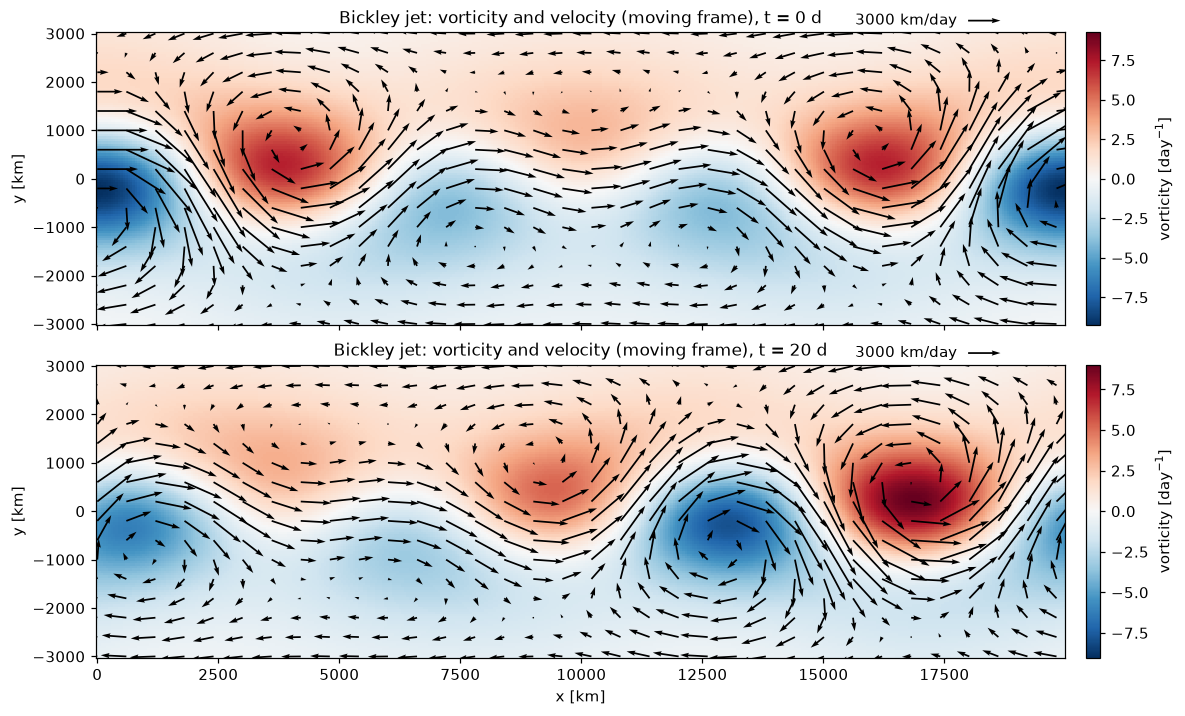

In [4]:
xg = np.linspace(0, Lx, 400, endpoint=False)
yg = np.linspace(-Y_MAX, Y_MAX, 121)
XG, YG = np.meshgrid(xg, yg)

u_key = float(f"{0.55 * bj.U0:.1g}")                   # a round speed for the arrow key
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, constrained_layout=True)
for ax, t in zip(axes, (0.0, T0)):
    lk.plot_field(ax, xg, yg, vorticity(XG, YG, t), kind="vorticity", robust=False,
                  label="vorticity [day$^{-1}$]")
    u, v = velocity(XG, YG, t)
    q = ax.quiver(XG[::8, ::12], YG[::8, ::12], u[::8, ::12], v[::8, ::12], scale=16.6 * bj.U0, width=0.0018)
    ax.quiverkey(q, 0.9, 1.04, u_key, f"{u_key:.0f} km/day", labelpos="W")
    ax.set(ylabel="y [km]", title=f"Bickley jet: vorticity and velocity (moving frame), t = {t:.3g} d", aspect="equal")
axes[-1].set_xlabel("x [km]")
plt.show()

**Discussion.** - The analytic vorticity agrees with finite differences to about $10^{-10}$ (relative to $U_0/L_0$) and the divergence is zero to the same level, so the formulas in `lagkit` are consistent with (B1.1).
- The eastward jet meanders between a row of **cyclones to the north** ($\omega>0$, red) and a row of **anticyclones to the south** ($\omega<0$, blue). In this moving frame the jet core flows east at about 3000 km/day and the water far from the jet flows west at $-c_3\approx-2500$ km/day.
- The pattern is not steady: compare the two times. The three waves travel at different speeds, so the eddies strengthen, weaken and shift relative to one another.
- From these snapshots alone you cannot tell which water stays inside an eddy and which is exchanged. That is the question the rest of the notebook answers.

<a id="B2"></a>
## B2. Trajectories (→ [A1](00-lagrangian-theory.ipynb#A1), [A9](00-lagrangian-theory.ipynb#A9))

The integrator is short enough to read in full. One RK4 step (A9.1), then the loop that applies it, freezes particles whose velocity is undefined (NaN) and records how long each one was integrated. The Bickley jet is defined everywhere, so nothing will be frozen here; this matters in notebook 02.

In [5]:
print(inspect.getsource(lk._rk4_step))
print(inspect.getsource(lk._march))

def _rk4_step(x, y, t, h, vel):
    """One classical RK4 step of size ``h`` (signed). NaN in any stage -> NaN."""
    k1u, k1v = vel(x, y, t)
    k2u, k2v = vel(x + 0.5 * h * k1u, y + 0.5 * h * k1v, t + 0.5 * h)
    k3u, k3v = vel(x + 0.5 * h * k2u, y + 0.5 * h * k2v, t + 0.5 * h)
    k4u, k4v = vel(x + h * k3u, y + h * k3v, t + h)
    xn = x + h / 6.0 * (k1u + 2.0 * k2u + 2.0 * k3u + k4u)
    yn = y + h / 6.0 * (k1v + 2.0 * k2v + 2.0 * k3v + k4v)
    return xn, yn

def _march(x0, y0, t0, T, dt, vel):
    """Generator behind all integrators.

    Yields ``(k, t, x, y, alive, tau)`` for k = 0..n, where ``alive`` flags
    particles still inside the valid field and ``tau`` is the elapsed time each
    particle has been integrated (>= 0, frozen at the exit time).
    """
    x = np.array(x0, dtype=float)
    y = np.array(y0, dtype=float)
    x, y = np.broadcast_arrays(x, y)
    x, y = x.copy(), y.copy()
    n, h = _time_steps(T, dt)
    alive = np.isfinite(x) & np.isfinite(y)
    tau = np

`lk.advect(x0, y0, t0, T, dt, vel, save_every=None, return_exit=False)` wraps this loop. `T < 0` integrates backward. Positions in $x$ are **not wrapped**: a particle that goes around the periodic domain keeps increasing $x$, which is what statistics need. We wrap only for plotting.

Three circular blobs (radius `R_BLOB`, 250 km by default) are released at $t=0$:

- in an **eddy core**: (4000, 880) km for the default jet;
- in the **jet core**: at $x$ = `X_JET` and the $y$ where $u$ is largest;
- in the **chaotic band** between the eddies and the edge: (2500, 1300) km for the default jet.

For any other jet the first and third positions are found automatically from the **stagnation points** of the velocity at $t=0$ (`lk.stagnation_points`): the strongest elliptic point north of the jet, and the saddle nearest to it. You can also set `RELEASE_EDDY` and `RELEASE_CHAOTIC` yourself in B0.

stagnation points at t = 0:  elli. (0, -577),  hype. (0, 2592),  elli. (4015, 772),  hype. (4015, -2387),  elli. (7705, -1358),  hype. (7705, 1925),  hype. (10008, -1615),  elli. (10008, 1704),  hype. (12310, 1925),  elli. (12310, -1358),  hype. (16000, -2387),  elli. (16000, 772)
jet core at x = 8000 km: y = 260 km, u = 3044 km/day


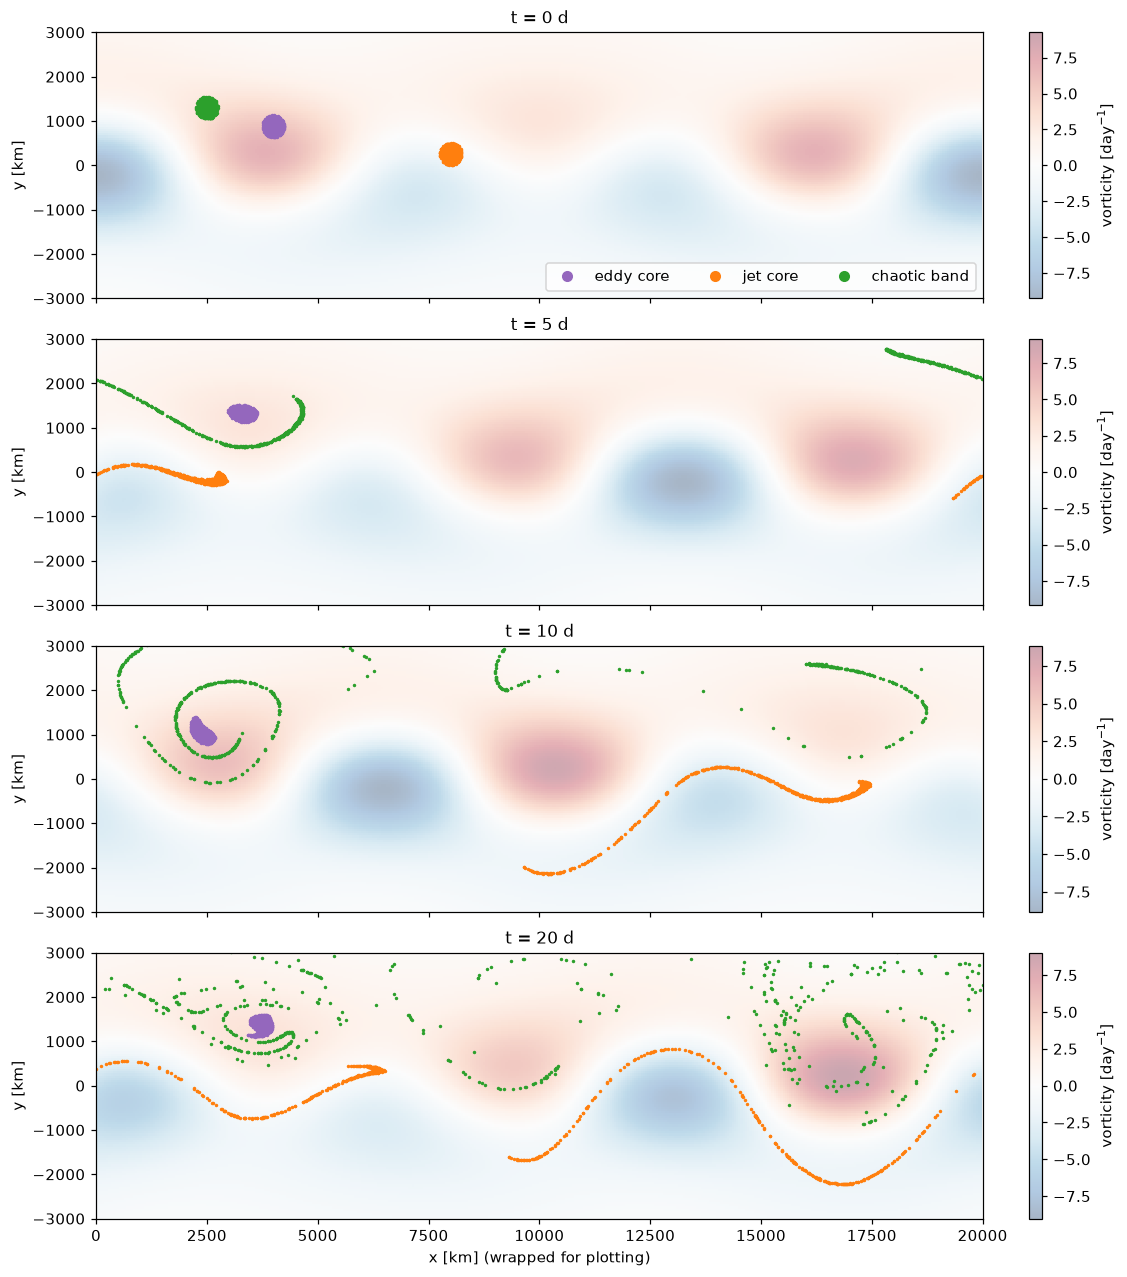

In [6]:
# Stagnation points of the velocity at t = 0: elliptic = centre of an eddy of the frozen
# field, hyperbolic = saddle. They are used to place the blobs when no position is given.
stag = lk.stagnation_points(velocity, xg, yg, 0.0, periodic_x=Lx)
print("stagnation points at t = 0:  " + ",  ".join(f"{p['kind'][:4]}. ({p['x']:.0f}, {p['y']:.0f})" for p in stag))
pdist = lambda p, q: np.hypot((p[0] - q[0] + Lx / 2) % Lx - Lx / 2, p[1] - q[1])   # periodic distance

if RELEASE_EDDY is None:
    north = [p for p in stag if p["kind"] == "elliptic" and p["y"] > 0]
    RELEASE_EDDY = (north[np.argmin([p["W"] for p in north])]["x"], north[np.argmin([p["W"] for p in north])]["y"]) \
        if north else (0.2 * Lx, 0.3 * Y_MAX)
    print(f"eddy-core blob placed automatically at ({RELEASE_EDDY[0]:.0f}, {RELEASE_EDDY[1]:.0f}) km"
          + ("" if north else "  (no elliptic point found: fallback position)"))
if RELEASE_CHAOTIC is None:
    saddles = [(p["x"], p["y"]) for p in stag if p["kind"] == "hyperbolic" and p["y"] * RELEASE_EDDY[1] > 0]
    RELEASE_CHAOTIC = min(saddles, key=lambda s: pdist(s, RELEASE_EDDY)) if saddles \
        else (RELEASE_EDDY[0] - 0.85 * L0, RELEASE_EDDY[1] + 0.24 * L0)
    print(f"chaotic-band blob placed automatically at ({RELEASE_CHAOTIC[0]:.0f}, {RELEASE_CHAOTIC[1]:.0f}) km"
          + ("  (nearest saddle)" if saddles else "  (no saddle found: fallback position)"))

y_line = np.linspace(-Y_MAX, Y_MAX, 6001)
y_jet = y_line[np.argmax(velocity(X_JET, y_line, 0.0)[0])]
print(f"jet core at x = {X_JET:.0f} km: y = {y_jet:.0f} km, u = {velocity(X_JET, y_jet, 0.0)[0]:.0f} km/day")

blobs = {"eddy core": tuple(RELEASE_EDDY), "jet core": (X_JET, y_jet), "chaotic band": tuple(RELEASE_CHAOTIC)}
blob_colors = {"eddy core": "tab:purple", "jet core": "tab:orange", "chaotic band": "tab:green"}
steps_per_snap = int(round(T_BLOB / 4 / DT_TRAJ))
snap_times = T_BLOB * np.array([0.0, 0.25, 0.5, 1.0])

blob_tracks = {}
for name, (xc, yc) in blobs.items():
    r = R_BLOB * np.sqrt(rng.uniform(0, 1, N_BLOB))           # uniform over the disc
    th = rng.uniform(0, 2 * np.pi, N_BLOB)
    X, Y, t = lk.advect(xc + r * np.cos(th), yc + r * np.sin(th), 0.0, T_BLOB, DT_TRAJ, velocity,
                        save_every=steps_per_snap)
    blob_tracks[name] = (X, Y, t)

fig, axes = plt.subplots(4, 1, figsize=(11, 11.5), sharex=True, constrained_layout=True)
for ax, day in zip(axes, snap_times):
    lk.plot_field(ax, xg, yg, vorticity(XG, YG, float(day)), kind="vorticity", robust=False,
                  alpha=0.35, label="vorticity [day$^{-1}$]")
    for name, (X, Y, t) in blob_tracks.items():
        i = int(np.argmin(np.abs(t - day)))
        ax.plot(np.mod(X[i], Lx), Y[i], ".", ms=2.5, color=blob_colors[name], label=name)
    ax.set(ylabel="y [km]", title=f"t = {day:.3g} d", aspect="equal", xlim=(0, Lx), ylim=(-Y_MAX, Y_MAX))
axes[0].legend(loc="lower right", markerscale=5, ncol=3)
axes[-1].set_xlabel("x [km] (wrapped for plotting)")
plt.show()

**Discussion.** Three releases a few hundred kilometres apart behave in three different ways.

- **Eddy core (purple):** the blob rotates and drifts with its eddy but stays compact for the whole 20 days.
- **Jet core (orange):** the blob is drawn out into a long thin filament by the shear, along the jet. It becomes very long but it stays in the jet and never leaks to either side.
- **Chaotic band (green):** the blob is stretched *and folded*. After 10 days it wraps around several eddies; after 20 days it is scattered over the whole northern side. Some particles go beyond the plotted range in $y$. Every green particle is still on the northern side of the orange filament: none has crossed the jet.

So the flow has regions that keep their water (eddy cores, jet core), a well-mixed region around the eddies, and a barrier (the jet) between north and south. The diagnostics of B3–B9 are different ways of finding these regions without having to guess where to put the blobs.

### B2b. A second tracking method: OceanParcels

Real velocity data come on a grid, and most people use a community code to advect particles in them. [OceanParcels](https://parcels-code.org) is the most widely used one in oceanography. To check our integrator against it:

1. sample the analytic jet on a grid ($\Delta x\approx100$ km, 6-hourly), as if it were model output. Neither interpolator knows that the flow is periodic, and a particle in the jet travels more than one period in 10 days, so the grid covers five periods in $x$;
2. advect the same particles with **(a)** our RK4 in the analytic field, **(b)** our RK4 in the gridded field with linear interpolation (`lk.grid_interpolator`), **(c)** OceanParcels (its RK4 kernel) in the same gridded field (`lk.advect_parcels`).

Comparing (b) with (c) tests the *integrators*. Comparing (a) with (b) shows the cost of *gridding and interpolating* the velocity ([A9](00-lagrangian-theory.ipynb#A9)).

grid: 7 periods in x, dx = 100 km, dy = 100 km, dt = 0.25 d
<xarray.Dataset> Size: 75MB
Dimensions:  (time: 41, y: 81, x: 1402)
Coordinates:
  * time     (time) float64 328B 0.0 0.25 0.5 0.75 1.0 ... 9.25 9.5 9.75 10.0
  * y        (y) float64 648B -4e+03 -3.9e+03 -3.8e+03 ... 3.8e+03 3.9e+03 4e+03
  * x        (x) float64 11kB -6.005e+04 -5.995e+04 ... 7.996e+04 8.006e+04
Data variables:
    u        (time, y, x) float64 37MB -2.615e+03 -2.614e+03 ... -2.244e+03
    v        (time, y, x) float64 37MB -4.123e-13 -17.59 ... -53.99 -60.33

three backends, 3 x 60 particles, 10 days: 5.5 s


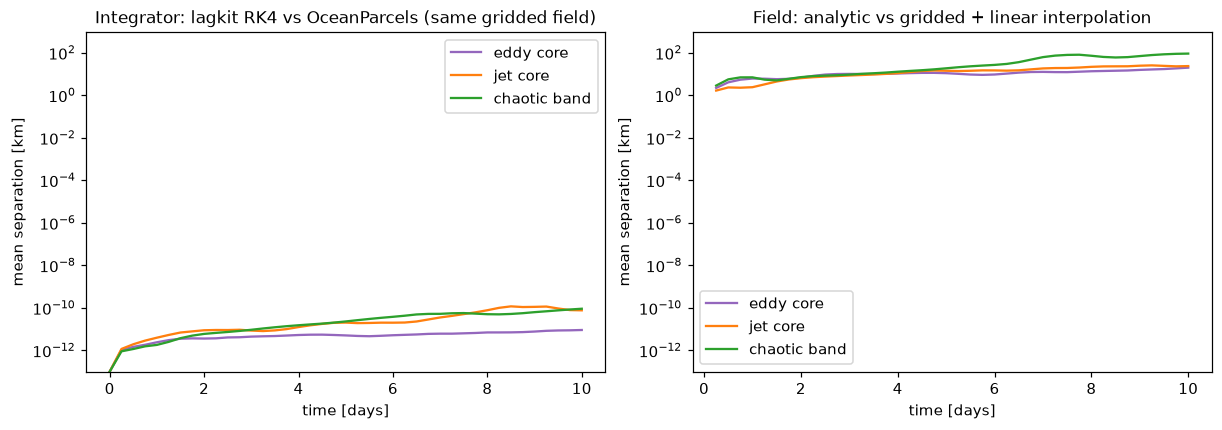

eddy core    : after 10 d  parcels vs lagkit = 9.1e-12 km,  analytic vs gridded =    19.9 km   (0 of 60 left the grid)
jet core     : after 10 d  parcels vs lagkit = 7.6e-11 km,  analytic vs gridded =    23.6 km   (0 of 60 left the grid)
chaotic band : after 10 d  parcels vs lagkit = 9.1e-11 km,  analytic vs gridded =    91.1 km   (0 of 60 left the grid)


In [7]:
# The grid must contain every particle for T_COMPARE days: count the periods travelled.
u_max = np.abs(velocity(XG, YG, 0.0)[0]).max()
n_per = int(np.ceil(1.2 * u_max * T_COMPARE / Lx))
x_grid = np.linspace(-n_per * Lx, (n_per + 1) * Lx, int(round((2 * n_per + 1) * Lx / GRID_DX)) + 1)
y_half = Y_MAX + 10 * GRID_DX
y_grid = np.linspace(-y_half, y_half, int(round(2 * y_half / GRID_DX)) + 1)
t_grid = np.arange(0, T_COMPARE + GRID_DT / 2, GRID_DT)
ds_grid = lk.sample_to_dataset(velocity, x_grid, y_grid, t_grid)
vel_grid = lk.grid_interpolator(ds_grid, "u", "v")
print(f"grid: {2 * n_per + 1} periods in x, dx = {x_grid[1] - x_grid[0]:.0f} km, dy = {y_grid[1] - y_grid[0]:.0f} km, dt = {GRID_DT:.3g} d")
print(ds_grid)

sep_interp, sep_parcels, n_exit = {}, {}, {}
N_RING = 60
tic = time.time()
for name, (xc, yc) in blobs.items():
    th = np.linspace(0, 2 * np.pi, N_RING, endpoint=False)
    x0, y0 = xc + R_BLOB * np.cos(th), yc + R_BLOB * np.sin(th)
    Xa, Ya, tt = lk.advect(x0, y0, 0.0, T_COMPARE, DT_TRAJ, velocity, save_every=5)                               # (a)
    Xb, Yb, _, tau_b = lk.advect(x0, y0, 0.0, T_COMPARE, DT_TRAJ, vel_grid, save_every=5, return_exit=True)       # (b)
    Xc, Yc, _, tau_c = lk.advect_parcels(x0, y0, 0.0, T_COMPARE, DT_TRAJ, ds_grid, save_every=5, return_exit=True)  # (c)
    inside = (tau_b >= T_COMPARE - 1e-9) & (tau_c >= T_COMPARE - 1e-9)   # particles that stayed on the grid
    n_exit[name] = (~inside).sum()
    sep_interp[name] = np.hypot(Xa - Xb, Ya - Yb)[:, inside].mean(axis=1)
    sep_parcels[name] = np.hypot(Xb - Xc, Yb - Yc)[:, inside].mean(axis=1)
print(f"\nthree backends, 3 x {N_RING} particles, {T_COMPARE:.3g} days: {time.time() - tic:.1f} s")

FLOOR = 1e-13                                                  # km: below round-off, for the log axis
top = 10 * max(np.nanmax(s) for s in list(sep_interp.values()) + list(sep_parcels.values()))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for name in blobs:
    axes[0].semilogy(tt, np.maximum(sep_parcels[name], FLOOR), color=blob_colors[name], label=name)
    axes[1].semilogy(tt[1:], np.maximum(sep_interp[name][1:], FLOOR), color=blob_colors[name], label=name)
axes[0].set(xlabel="time [days]", ylabel="mean separation [km]", ylim=(FLOOR, top),
            title="Integrator: lagkit RK4 vs OceanParcels (same gridded field)")
axes[1].set(xlabel="time [days]", ylabel="mean separation [km]", ylim=(FLOOR, top),
            title="Field: analytic vs gridded + linear interpolation")
for ax in axes:
    ax.legend()
plt.show()
for name in blobs:
    print(f"{name:13s}: after {T_COMPARE:.3g} d  parcels vs lagkit = {sep_parcels[name][-1]:.1e} km,"
          f"  analytic vs gridded = {sep_interp[name][-1]:7.1f} km   ({n_exit[name]} of {N_RING} left the grid)")

**Discussion.** - **Left panel.** In the same gridded field, our RK4 and OceanParcels agree to about $10^{-11}$ km after 10 days. That is round-off: both implement (A9.1), so this is the expected result, and it validates the integrator used in the rest of the course.
- **Right panel.** Replacing the analytic velocity by a 100 km, 6-hourly grid with linear interpolation moves the particles by a few kilometres within the first day, and by about 20 km (eddy core), 24 km (jet core) and 90 km (chaotic band) after 10 days. In the chaotic band the error keeps growing, as any error does there.
- The lesson for real data: the **resolution of the velocity field and the interpolation** limit the accuracy of trajectories, by many orders of magnitude more than the choice between two correct integrators. Halving the time step will not fix a coarse or gappy field.
- Two practical notes on OceanParcels (version 4). By default it treats a NaN or off-grid velocity as *zero*, so particles that reach land or the edge of the data silently stop being advected; `lk.advect_parcels` adds a kernel that freezes and flags them, like `lk.advect`. And it is slower than plain numpy for this kind of problem, which is why the maps below use `lk.advect`. Its strength is everything we do not need here: curvilinear and unstructured model grids, 3-D, large files read lazily, and custom particle behaviour.

<a id="B3"></a>
## B3. Single-particle statistics (→ [A2](00-lagrangian-theory.ipynb#A2))

Release `N_SINGLE` particles at random over the domain and follow them for 30 days. We compute the absolute dispersion (A2.1) per component, the velocity autocorrelations (A2.2), the integral time scale (A2.3, cut at the first zero crossing) and the diffusivity estimate $K=\langle u'^2\rangle T_L$ (A2.6).

In [8]:
x0 = rng.uniform(0, Lx, N_SINGLE)
y0 = rng.uniform(-Y_REL, Y_REL, N_SINGLE)
Xs, Ys, ts = lk.advect(x0, y0, 0.0, T_SINGLE, DT_TRAJ, velocity, save_every=2)
dts = ts[1] - ts[0]

Ax2, Ay2, n_part = lk.absolute_dispersion(Xs, Ys)
Us, Vs = velocity(Xs, Ys, ts[:, None])                 # velocity along the trajectories
var_u, var_v = Us.var(), Vs.var()

max_lag = int(round(MAX_LAG / dts))
Ru = lk.lagrangian_autocorr(Us, max_lag)
Rv = lk.lagrangian_autocorr(Vs, max_lag)
lags = np.arange(max_lag + 1) * dts
TLu, iu = lk.integral_timescale(Ru, dts)
TLv, iv = lk.integral_timescale(Rv, dts)
Ku, Kv = var_u * TLu, var_v * TLv

print(f"<u'^2> = {var_u:.3g} km^2/day^2 (rms {np.sqrt(var_u):.0f} km/day),  <v'^2> = {var_v:.3g} (rms {np.sqrt(var_v):.0f} km/day)")
for nm, TL, i0, K in (("u", TLu, iu, Ku), ("v", TLv, iv, Kv)):
    crossed = f"first zero of R at {lags[i0]:.2f} d" if i0 <= max_lag else f"R never crosses zero within {lags[-1]:.3g} d -> lower bound"
    print(f"T_L({nm}) = {TL:6.2f} d  ({crossed});  K = <{nm}'^2> T_L = {K:.2e} km^2/day = {K * KM2_DAY_TO_M2_S:.2e} m^2/s")
print(f"A_y at {T_SINGLE:.3g} d: {np.sqrt(Ay2[-1]):.0f} km rms;  A_x at {T_SINGLE:.3g} d: {np.sqrt(Ax2[-1]):.0f} km rms")

<u'^2> = 4.19e+06 km^2/day^2 (rms 2046 km/day),  <v'^2> = 2.37e+06 (rms 1538 km/day)
T_L(u) =  10.58 d  (R never crosses zero within 20 d -> lower bound);  K = <u'^2> T_L = 4.43e+07 km^2/day = 5.12e+08 m^2/s
T_L(v) =   0.37 d  (first zero of R at 0.70 d);  K = <v'^2> T_L = 8.64e+05 km^2/day = 1.00e+07 m^2/s
A_y at 30 d: 1409 km rms;  A_x at 30 d: 44803 km rms


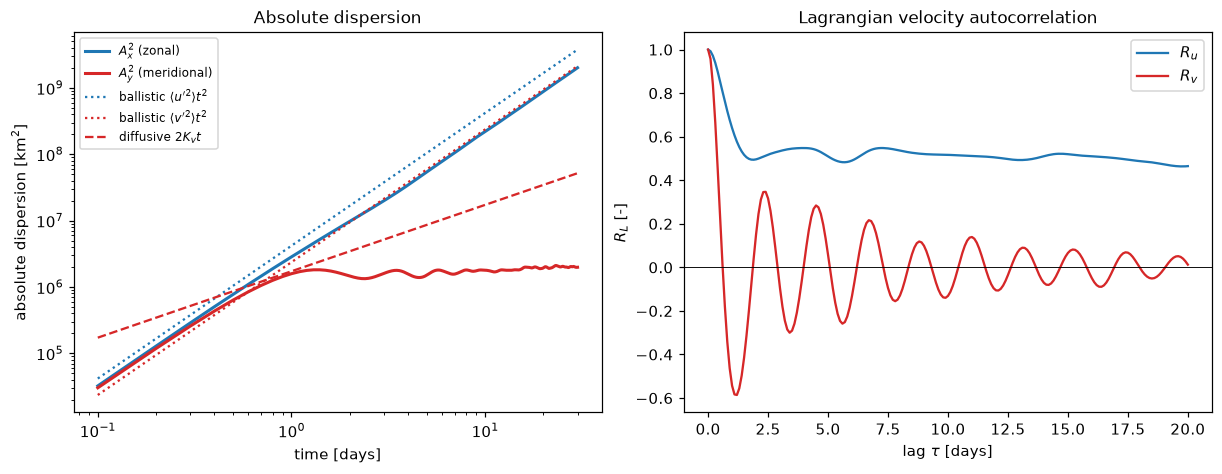

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
ax = axes[0]
tpos = ts[1:]
ax.loglog(tpos, Ax2[1:], color="tab:blue", lw=2, label="$A_x^2$ (zonal)")
ax.loglog(tpos, Ay2[1:], color="tab:red", lw=2, label="$A_y^2$ (meridional)")
ax.loglog(tpos, var_u * tpos ** 2, color="tab:blue", ls=":", label=r"ballistic $\langle u'^2\rangle t^2$")
ax.loglog(tpos, var_v * tpos ** 2, color="tab:red", ls=":", label=r"ballistic $\langle v'^2\rangle t^2$")
ax.loglog(tpos, 2 * Kv * tpos, color="tab:red", ls="--", label=r"diffusive $2K_vt$")
ax.set(xlabel="time [days]", ylabel="absolute dispersion [km$^2$]", title="Absolute dispersion")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(lags, Ru, color="tab:blue", label="$R_u$")
ax.plot(lags, Rv, color="tab:red", label="$R_v$")
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel=r"lag $\tau$ [days]", ylabel="$R_L$ [-]", title="Lagrangian velocity autocorrelation")
ax.legend()
plt.show()

**Discussion.** - **Both components are ballistic at first** ($A^2\propto t^2$, dotted lines) for $t\lesssim0.5$ day, as (A2.5) predicts.
- **Meridional.** $A_y^2$ stops growing after about one day and stays near $2\times10^6$ km² (rms displacement about 1400 km) for the remaining 29 days. Particles oscillate within their own eddy or their own side of the jet, and do not cross it (Exercise 4 tests this directly). The curve never follows the diffusive line $2K_vt$. Correspondingly $R_v$ oscillates with a period of about 2.2 days (the rotation of the eddies and the passage of the waves) and its first zero is at 0.7 day, giving $T_L\approx0.37$ day. The number $K_v=\langle v'^2\rangle T_L\approx10^7$ m²/s can be computed, but it does **not** describe the spreading: the jet is a meridional barrier, not a diffuser.
- **Zonal.** $A_x^2$ keeps growing like $t^2$ for 30 days, parallel to the ballistic line. $R_u$ levels off near 0.5 and never reaches zero: a particle in the jet keeps moving east and a particle outside keeps moving west. This is shear dispersion by the mean flow, and $T_L(u)$, hence $K_u$, is only a lower bound that depends on where the integral is cut.
- **Take-home.** Before quoting a diffusivity, check the two things Taylor's theory needs: that $R_L$ decays to zero, and that $A^2$ actually grows linearly in time. Neither holds here, in either direction. With real data the same problems appear through mean shear, coasts and the finite radar footprint.

<a id="B4"></a>
## B4. Relative dispersion (→ [A3](00-lagrangian-theory.ipynb#A3))

Release `N_PAIRS` pairs with initial separation $\delta_0=20$ km in random directions and follow them for 40 days. Because the domain is periodic, the $x$ separation uses the **minimum-image convention**: two particles are never counted as more than $L_x/2$ apart in $x$.

In [10]:
xa = rng.uniform(0, Lx, N_PAIRS)
ya = rng.uniform(-Y_REL, Y_REL, N_PAIRS)
ang = rng.uniform(0, 2 * np.pi, N_PAIRS)
XA, YA, tp = lk.advect(xa, ya, 0.0, T_PAIRS, DT_TRAJ, velocity, save_every=2)
XB, YB, _ = lk.advect(xa + DELTA0 * np.cos(ang), ya + DELTA0 * np.sin(ang), 0.0, T_PAIRS, DT_TRAJ,
                      velocity, save_every=2)
D = lk.pair_separation(XA, YA, XB, YB, periodic_x=Lx)           # (nt, npairs)
D2, Krel, kurt, n_pairs = lk.relative_dispersion(D, tp)

m = (tp >= FIT[0]) & (tp <= FIT[1])                             # early window
slope, intercept = np.polyfit(tp[m], np.log(D2[m]), 1)
lam_D2 = slope / 2
rate_lnD = np.polyfit(tp[m], np.log(D[m]).mean(axis=1), 1)[0]
m2 = (tp >= LOGLOG[0]) & (tp <= LOGLOG[1])
loglog_slope = np.polyfit(np.log(tp[m2]), np.log(D2[m2]), 1)[0]
D2_sat = Lx ** 2 / 12 + 2 * Ay2[-1]                             # x uniform over a period + independent y

print(f"exponential fit of <D^2> over {FIT[0]:.3g}-{FIT[1]:.3g} d:  lambda = {lam_D2:.2f} 1/day   (<D^2> ~ exp(2 lambda t))")
print(f"growth rate of <ln D> over the same window:  {rate_lnD:.2f} 1/day")
print(f"log-log slope of <D^2> between {LOGLOG[0]:.3g} and {LOGLOG[1]:.3g} d:   {loglog_slope:.2f}")
print(f"kurtosis: max {kurt.max():.0f} at t = {tp[kurt.argmax()]:.1f} d, final {kurt[-1]:.1f}")
for day in T_PAIRS * np.array([0.025, 0.075, 0.125, 0.25, 0.5, 1.0]):
    i = int(np.argmin(np.abs(tp - day)))
    print(f"  t = {day:4.3g} d: rms D = {np.sqrt(D2[i]):6.0f} km, median D = {np.median(D[i]):6.0f} km")

exponential fit of <D^2> over 0.5-3 d:  lambda = 0.80 1/day   (<D^2> ~ exp(2 lambda t))
growth rate of <ln D> over the same window:  0.31 1/day
log-log slope of <D^2> between 5 and 15 d:   2.04
kurtosis: max 99 at t = 5.1 d, final 2.6
  t =    1 d: rms D =     47 km, median D =     31 km
  t =    3 d: rms D =    219 km, median D =     51 km
  t =    5 d: rms D =    651 km, median D =     76 km
  t =   10 d: rms D =   1389 km, median D =    182 km
  t =   20 d: rms D =   3078 km, median D =    658 km
  t =   40 d: rms D =   4914 km, median D =   2832 km


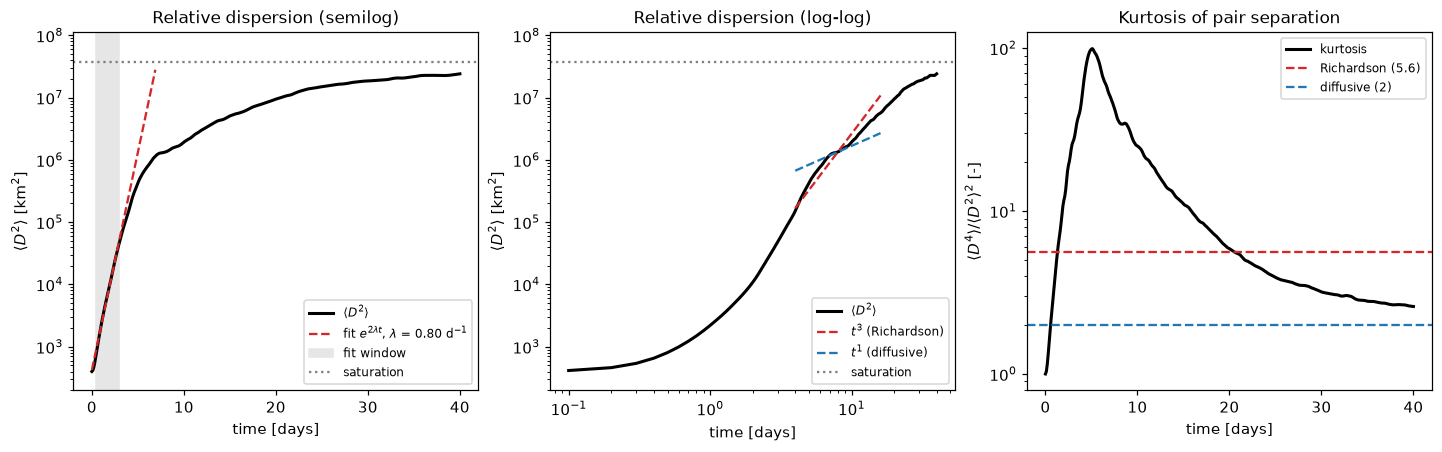

In [11]:
d2_lim = (0.5 * DELTA0 ** 2, 3 * max(D2_sat, D2.max()))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
ax = axes[0]
ax.semilogy(tp, D2, "k", lw=2, label=r"$\langle D^2\rangle$")
tf = np.linspace(0, min(2.3 * FIT[1], T_PAIRS), 50)
ax.semilogy(tf, np.exp(intercept + slope * tf), "tab:red", ls="--",
            label=rf"fit $e^{{2\lambda t}}$, $\lambda$ = {lam_D2:.2f} d$^{{-1}}$")
ax.axvspan(*FIT, color="0.9", label="fit window")
ax.axhline(D2_sat, color="0.5", ls=":", label="saturation")
ax.set(xlabel="time [days]", ylabel=r"$\langle D^2\rangle$ [km$^2$]", title="Relative dispersion (semilog)",
       ylim=d2_lim)
ax.legend(fontsize=8)

ax = axes[1]
ax.loglog(tp[1:], D2[1:], "k", lw=2, label=r"$\langle D^2\rangle$")
tr = np.array([0.8 * LOGLOG[0], 1.07 * LOGLOG[1]])              # reference slopes around the log-log window
i_ref = int(np.argmin(np.abs(tp - np.sqrt(tr[0] * tr[1]))))
ax.loglog(tr, D2[i_ref] * (tr / tp[i_ref]) ** 3, "tab:red", ls="--", label="$t^3$ (Richardson)")
ax.loglog(tr, D2[i_ref] * (tr / tp[i_ref]) ** 1, "tab:blue", ls="--", label="$t^1$ (diffusive)")
ax.axhline(D2_sat, color="0.5", ls=":", label="saturation")
ax.set(xlabel="time [days]", ylabel=r"$\langle D^2\rangle$ [km$^2$]", title="Relative dispersion (log-log)",
       ylim=d2_lim)
ax.legend(fontsize=8)

ax = axes[2]
ax.semilogy(tp, kurt, "k", lw=2, label="kurtosis")
ax.axhline(5.6, color="tab:red", ls="--", label="Richardson (5.6)")
ax.axhline(2.0, color="tab:blue", ls="--", label="diffusive (2)")
ax.set(xlabel="time [days]", ylabel=r"$\langle D^4\rangle/\langle D^2\rangle^2$ [-]", title="Kurtosis of pair separation")
ax.legend(fontsize=8)
plt.show()

**Discussion.** - **Early exponential growth.** Over 0.5–3 days $\langle D^2\rangle$ is a straight line on the semilog plot, with $\lambda\approx0.8$ day⁻¹ (non-local regime of [A3](00-lagrangian-theory.ipynb#A3)).
- **The pairs are very unequal.** After 5 days the rms separation is about 650 km while the *median* is only 76 km: half of the pairs have barely separated. The kurtosis peaks near 100 at 5 days. The mean is carried by a small number of fast pairs.
- **An apparent power law.** Between about 4 and 15 days the log-log curve bends from steeper than $t^3$ to a slope of about 2, and a segment of it is tangent to the $t^3$ line. It is tempting to call this a Richardson regime. It is not: this flow consists of three large waves, with no turbulence and no inertial range. The segment is the transition from exponential growth to saturation (dotted line), smeared out because pairs leave the exponential regime at different times.
- The kurtosis also passes through the Richardson value 5.6 (at about 21 days) on its way down towards 2–3. Passing through a value is not evidence either; in a real Richardson regime the kurtosis would *stay* there.
- With real data, where the range of scales between the grid spacing and the domain size is often only one decade, this artefact is the rule and not the exception.

<a id="B5"></a>
## B5. FSLE statistic (→ [A4](00-lagrangian-theory.ipynb#A4))

The same pairs, now analysed at fixed scale. This is the whole algorithm:

In [12]:
print(inspect.getsource(lk.fsle_statistic))

def fsle_statistic(D, t, delta0, r=np.sqrt(2.0), n_max=None):
    """Finite-size Lyapunov exponent as a pair statistic (Aurell et al. 1997).

    Thresholds ``delta_n = delta0 * r**n``. For each pair, ``tau_n`` is the time
    between the first crossings of ``delta_n`` and ``delta_{n+1}`` (crossing
    times are linearly interpolated between samples). Then
    ``lambda(delta_n) = ln(r) / <tau_n>``, averaged over the pairs that reach
    ``delta_{n+1}`` -- report the pair count, it is a survivorship-biased sample.

    Pairs may be released at different separations (for example delta0, delta0*r,
    delta0*r**2, ...) to populate the large scales: a pair contributes to a
    threshold only if it started at or below it.

    Parameters
    ----------
    D : array (nt, npairs) [L]; NaN after a pair is lost
    t : array (nt,) [T];  delta0 : float [L], smallest threshold;  r : float > 1

    Returns
    -------
    delta : (n,) [L];  lam : (n,) [1/T];  npairs : (n,) int;  tau_mean : (n,) [

FSLE plateau (20-1000 km): 0.19 1/day
rate from <D^2> fit (B4):  0.80 1/day
rate of <ln D> (B4):       0.31 1/day


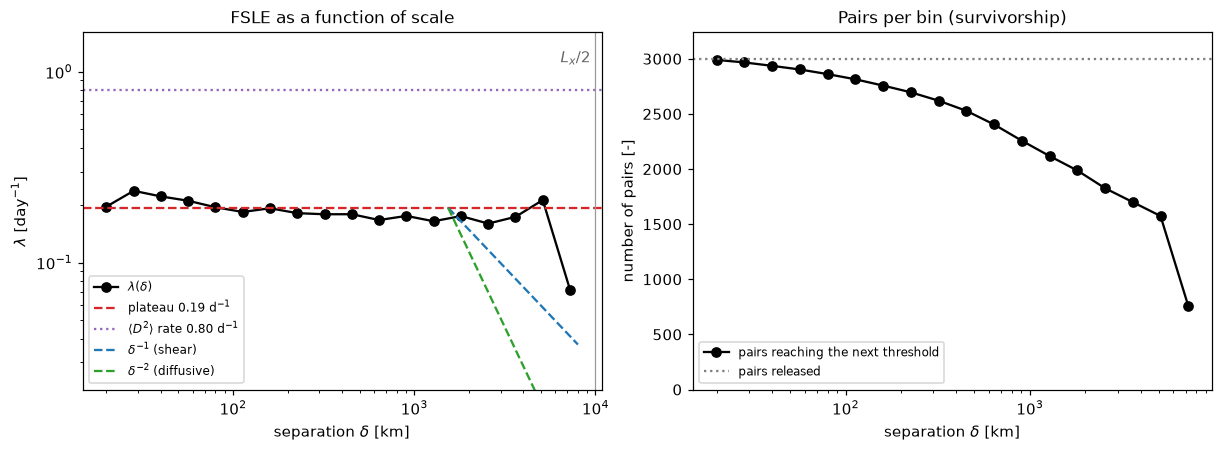

In [13]:
delta, lam_fsle, n_bin, tau_mean = lk.fsle_statistic(D, tp, DELTA0)
plateau = np.nanmean(lam_fsle[(delta >= PLATEAU[0]) & (delta <= PLATEAU[1])])
print(f"FSLE plateau ({PLATEAU[0]:.0f}-{PLATEAU[1]:.0f} km): {plateau:.2f} 1/day")
print(f"rate from <D^2> fit (B4):  {lam_D2:.2f} 1/day")
print(f"rate of <ln D> (B4):       {rate_lnD:.2f} 1/day")

good = np.isfinite(lam_fsle) & (lam_fsle > 0)
lam_lim = (0.3 * lam_fsle[good].min(), 2 * max(lam_fsle[good].max(), lam_D2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax = axes[0]
ax.loglog(delta[good], lam_fsle[good], "o-", color="k", label=r"$\lambda(\delta)$")
ax.axhline(plateau, color="tab:red", ls="--", label=f"plateau {plateau:.2f} d$^{{-1}}$")
ax.axhline(lam_D2, color="tab:purple", ls=":", label=rf"$\langle D^2\rangle$ rate {lam_D2:.2f} d$^{{-1}}$")
dref = np.array([Lx / 13, Lx / 2.5])                           # reference slopes, anchored on the plateau
ax.loglog(dref, plateau * (dref / dref[0]) ** -1, color="tab:blue", ls="--", label=r"$\delta^{-1}$ (shear)")
ax.loglog(dref, plateau * (dref / dref[0]) ** -2, color="tab:green", ls="--", label=r"$\delta^{-2}$ (diffusive)")
ax.axvline(Lx / 2, color="0.6", lw=0.8)
ax.text(Lx / 2, 0.8 * lam_lim[1], "$L_x/2$ ", ha="right", va="top", color="0.4")
ax.set(xlabel=r"separation $\delta$ [km]", ylabel=r"$\lambda$ [day$^{-1}$]", ylim=lam_lim,
       title="FSLE as a function of scale")
ax.legend(fontsize=8, loc="lower left")

ax = axes[1]
ax.semilogx(delta, n_bin, "o-", color="k", label="pairs reaching the next threshold")
ax.axhline(N_PAIRS, color="0.5", ls=":", label="pairs released")
ax.set(xlabel=r"separation $\delta$ [km]", ylabel="number of pairs [-]", ylim=(0, N_PAIRS * 1.08),
       title="Pairs per bin (survivorship)")
ax.legend(fontsize=8, loc="lower left")
plt.show()

**Discussion.** - **A plateau.** $\lambda(\delta)\approx0.19$ day⁻¹ from 20 km up to several thousand km. Separation is exponential at all scales below the size of the waves, because the stirring is done by the large waves only (non-local regime). There is no range where $\lambda$ decays like $\delta^{-1}$ or $\delta^{-2}$ before the scale $L_x/2$, beyond which the minimum-image separation cannot grow. The clean plateau replaces the ambiguous curve of B4.
- **Pairs per bin.** The count falls from about 3000 to about 1600 at large $\delta$: nearly half of the pairs, those released in eddy cores or in the jet, never get that far apart in 40 days. The last point (750 pairs, low $\lambda$) is not reliable, both for that reason and because of the periodic domain.
- **Two very different rates.** The fit to $\langle D^2\rangle$ gave 0.80 day⁻¹, four times the FSLE. Both are correct; they answer different questions. $\langle D^2\rangle$ is dominated by the fastest pairs (A4.3), which is exactly what the kurtosis of 100 in B4 says. The FSLE averages times and gives the typical pair. The growth rate of $\langle\ln D\rangle$ over the same early window, 0.31 day⁻¹, lies in between and much closer to the FSLE.
- Keep the plateau value in mind: the domain-averaged FTLE of B6 will turn out to be the same number.

<a id="B6"></a>
## B6. FTLE (→ [A5](00-lagrangian-theory.ipynb#A5))

Release one particle per grid point at $t_0=20$ d, integrate for $|T|=20$ d forward and backward, differentiate the flow map by centred differences and apply (A5.2)–(A5.3):

In [14]:
print(inspect.getsource(lk._ftle_from_gradients))

def _ftle_from_gradients(Fxx, Fxy, Fyx, Fyy, T):
    """FTLE from the flow-map gradient; closed-form largest eigenvalue of C."""
    C11 = Fxx ** 2 + Fyx ** 2
    C12 = Fxx * Fxy + Fyx * Fyy
    C22 = Fxy ** 2 + Fyy ** 2
    lam2 = 0.5 * (C11 + C22) + np.sqrt(0.25 * (C11 - C22) ** 2 + C12 ** 2)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.log(lam2) / (2.0 * np.abs(T))



In [15]:
xf_ = np.linspace(0, Lx, NX_FTLE, endpoint=False)      # one period, end point not repeated
yf_ = np.linspace(-Y_MAX, Y_MAX, NY_FTLE)
XF0, YF0 = np.meshgrid(xf_, yf_)
dxf, dyf = xf_[1] - xf_[0], yf_[1] - yf_[0]


def ftle_field(T):
    # FTLE at t0 = T0 for a signed integration time T [days]
    xf, yf = lk.advect(XF0, YF0, T0, T, DT, velocity)
    return lk.ftle_from_flowmap(xf, yf, dxf, dyf, T, periodic_x=Lx)


tic = time.time()
ftle_fwd = ftle_field(+T_FTLE)
ftle_bwd = ftle_field(-T_FTLE)
print(f"grid {NX_FTLE} x {NY_FTLE} (dx = {dxf:.0f} km), 2 x {XF0.size} particles: {time.time() - tic:.1f} s")
print(f"domain-mean FTLE: forward {ftle_fwd.mean():.3f}, backward {ftle_bwd.mean():.3f} 1/day")
print(f"compare: FSLE plateau {plateau:.2f}, <ln D> rate {rate_lnD:.2f}, <D^2> rate {lam_D2:.2f} 1/day")

grid 400 x 121 (dx = 50 km), 2 x 48400 particles: 7.1 s
domain-mean FTLE: forward 0.198, backward 0.198 1/day
compare: FSLE plateau 0.19, <ln D> rate 0.31, <D^2> rate 0.80 1/day


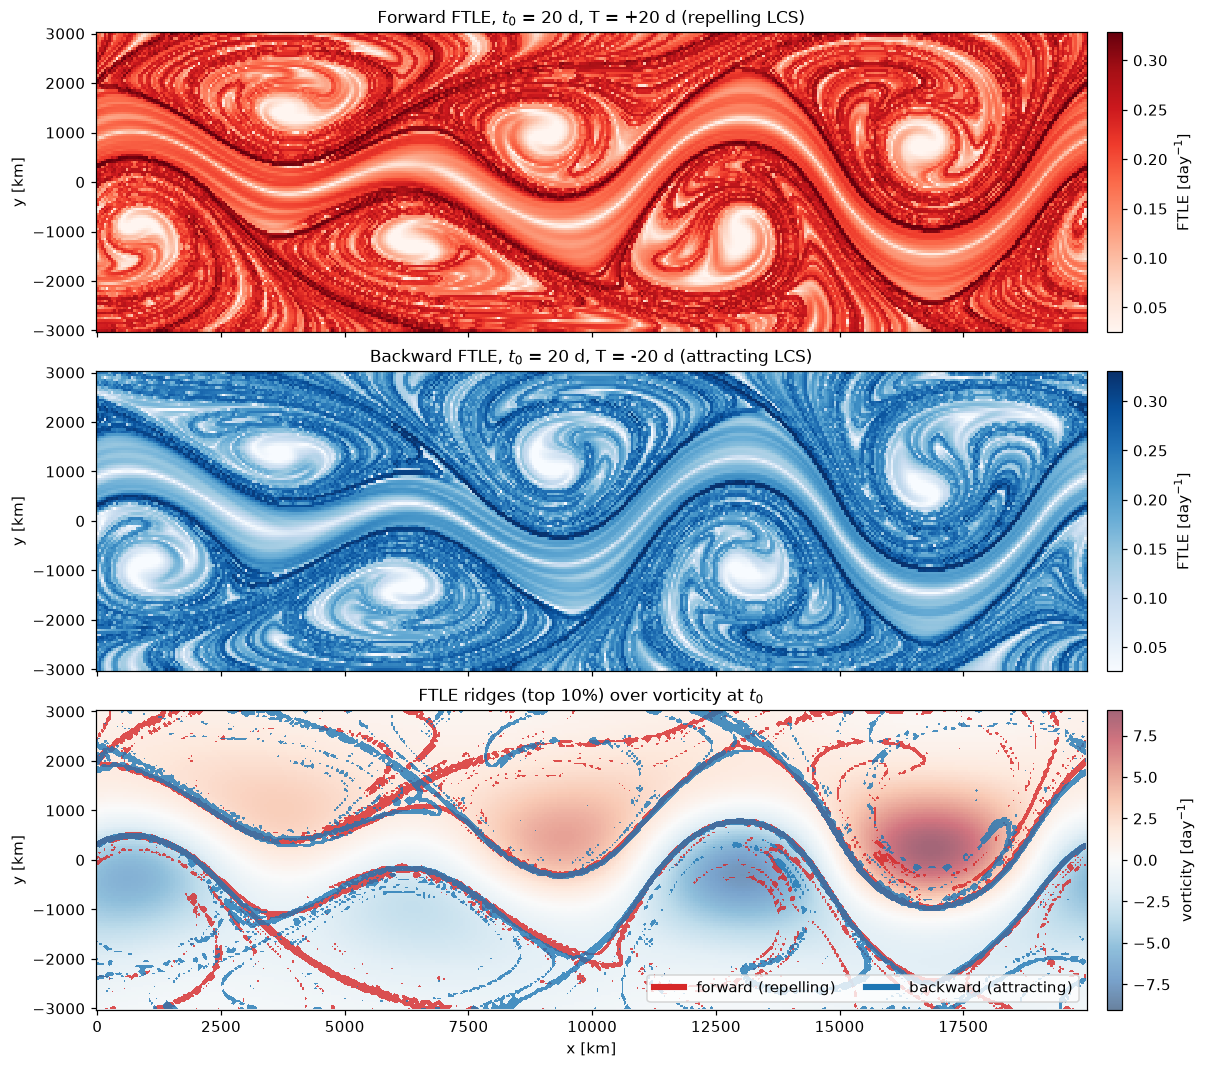

In [16]:
vort_t0 = vorticity(XF0, YF0, T0)
fig, axes = plt.subplots(3, 1, figsize=(11, 9.6), sharex=True, constrained_layout=True)
lk.plot_field(axes[0], xf_, yf_, ftle_fwd, kind="ftle_fwd", label="FTLE [day$^{-1}$]",
              title=f"Forward FTLE, $t_0$ = {T0:.3g} d, T = +{T_FTLE:.3g} d (repelling LCS)")
lk.plot_field(axes[1], xf_, yf_, ftle_bwd, kind="ftle_bwd", label="FTLE [day$^{-1}$]",
              title=f"Backward FTLE, $t_0$ = {T0:.3g} d, T = -{T_FTLE:.3g} d (attracting LCS)")
lk.plot_field(axes[2], xf_, yf_, vort_t0, kind="vorticity", robust=False, alpha=0.6,
              label="vorticity [day$^{-1}$]", title="FTLE ridges (top 10%) over vorticity at $t_0$")
axes[2].contourf(xf_, yf_, ftle_fwd, levels=[np.quantile(ftle_fwd, 0.9), np.inf], colors=["tab:red"], alpha=0.8)
axes[2].contourf(xf_, yf_, ftle_bwd, levels=[np.quantile(ftle_bwd, 0.9), np.inf], colors=["tab:blue"], alpha=0.8)
axes[2].legend(handles=[Line2D([], [], color="tab:red", lw=4, label="forward (repelling)"),
                        Line2D([], [], color="tab:blue", lw=4, label="backward (attracting)")],
               loc="lower right", ncol=2)
for ax in axes:
    ax.set(ylabel="y [km]", aspect="equal")
axes[-1].set_xlabel("x [km]")
plt.show()

**Discussion.** - **Low FTLE (pale)** in the six eddy cores and along the core of the jet: the regions that kept their blobs together in B2.
- **Two strong ridges follow the flanks of the jet**, in the forward *and* in the backward map, almost on top of each other (bottom panel). Material on either side of these lines ends up far apart, in both time directions. Together they bound the jet core, which nothing crosses: this is the meridional barrier seen in B3.
- **Around the eddies** the ridges spiral and the forward (red) and backward (blue) families cross each other. The crossings between neighbouring eddies mark hyperbolic points; the lobes enclosed between the two families are the parcels of water exchanged between an eddy's surroundings and the chaotic band.
- The domain-mean FTLE is 0.198 day⁻¹ in both directions, equal to the FSLE plateau of B5 (0.19). The two-particle statistic and the map measure the same typical stretching rate; the map shows *where* it happens.
- Not every ridge is a hyperbolic LCS. The jet-flank ridges owe much of their strength to shear. Exercise 2 looks at this.

**Sensitivity to the integration time.** The same forward calculation for the integration times in `T_LIST` (5, 10 and 30 days by default).

T =     5 d: mean FTLE = 0.408, max = 1.074 1/day,  dx*exp(max*T) = 1.1e+04 km
T =    10 d: mean FTLE = 0.285, max = 0.626 1/day,  dx*exp(max*T) = 2.6e+04 km
T =    30 d: mean FTLE = 0.152, max = 0.250 1/day,  dx*exp(max*T) = 9.0e+04 km


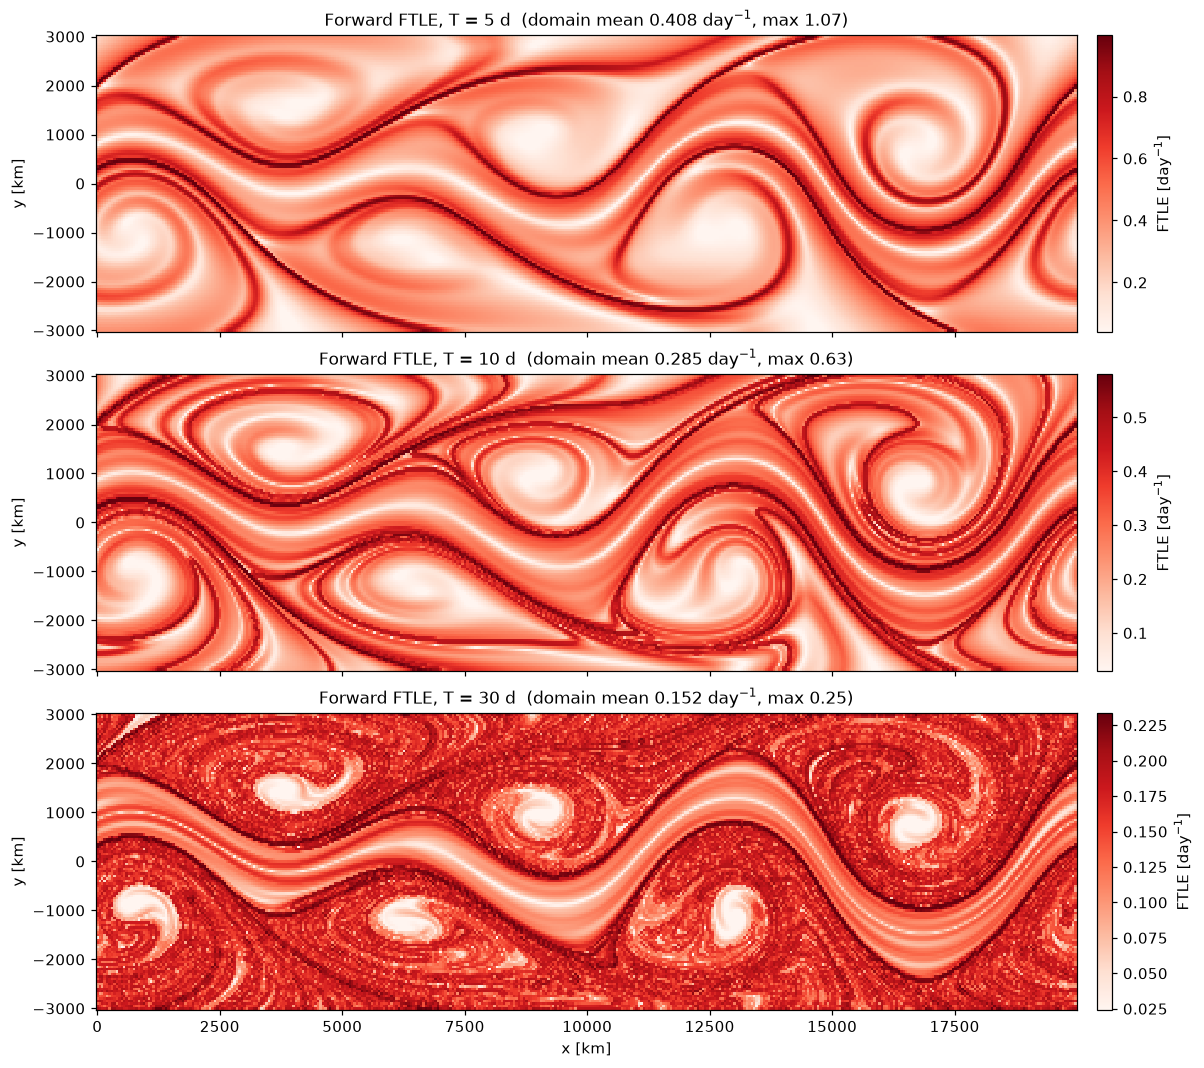

In [17]:
fig, axes = plt.subplots(len(T_LIST), 1, figsize=(11, 3.2 * len(T_LIST)), sharex=True, constrained_layout=True)
mean_ftle = {T_FTLE: ftle_fwd.mean()}
for ax, T in zip(np.atleast_1d(axes), T_LIST):
    f = ftle_field(T)
    mean_ftle[T] = f.mean()
    lk.plot_field(ax, xf_, yf_, f, kind="ftle_fwd", label="FTLE [day$^{-1}$]",
                  title=f"Forward FTLE, T = {T:.3g} d  (domain mean {f.mean():.3f} day$^{{-1}}$, max {f.max():.2f})")
    ax.set(ylabel="y [km]", aspect="equal")
    print(f"T = {T:5.3g} d: mean FTLE = {f.mean():.3f}, max = {f.max():.3f} 1/day,"
          f"  dx*exp(max*T) = {dxf * np.exp(f.max() * T):.1e} km")
np.atleast_1d(axes)[-1].set_xlabel("x [km]")
plt.show()

**Discussion.** - **$T=5$ d:** few, broad ridges and large values (mean 0.41, maximum 1.07 day⁻¹). The map is still close to an Eulerian strain map.
- **$T=10$ d:** more ridges, thinner, and the low-FTLE eddy cores are clearly outlined.
- **$T=30$ d:** the mean has dropped to 0.15 day⁻¹ and the contrast is lower, as expected when $T$ grows ([A5](00-lagrangian-theory.ipynb#A5)). The eddy cores and the jet are still smooth, but the chaotic regions have turned into **speckle**. This is aliasing ([A9](00-lagrangian-theory.ipynb#A9)): the printed $\Delta x\,e^{\sigma_{max}T}$ is far larger than the domain, so neighbouring grid particles have lost all relation to each other and the finite difference is no longer a derivative. The ridges are thinner than the 50 km grid. A finer grid, not a smaller time step, is the cure (Exercise 1).
- The pale eddy cores **shrink** as $T$ increases: the longer the time over which you ask water to stay together, the less water qualifies.
- Choosing $T$ is part of the question, not a numerical detail. With radar data the choice is further limited by how long particles stay inside the coverage.

<a id="B7"></a>
## B7. FSLE map (→ [A6](00-lagrangian-theory.ipynb#A6))

Backward FSLE map with $\delta_0=20$ km and $\delta_f=600$ km (about the eddy size), maximum integration time 20 days, next to the backward FTLE of B6 at the same $t_0$. Each grid point needs five particles (the point and four neighbours), so this is the most expensive map of the notebook; the grid is a little coarser.

grid 300 x 91, 5 x 27300 particles: 11.2 s
points that reached delta_f: 80%   (lambda = 0 elsewhere)
smallest non-zero value possible: ln(delta_f/delta_0)/T_max = 0.170 1/day
largest value: 1.97 1/day, i.e. delta_f reached in 1.7 d


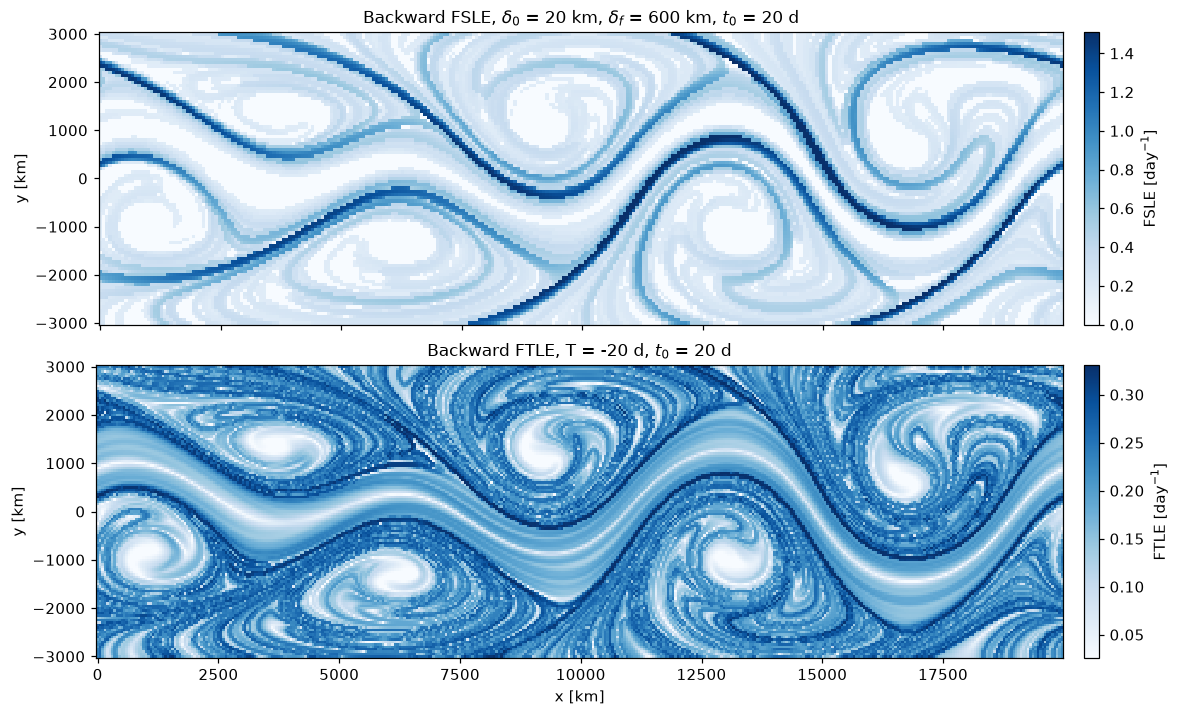

In [18]:
xs7 = np.linspace(0, Lx, NX_FSLE, endpoint=False)
ys7 = np.linspace(-Y_MAX, Y_MAX, NY_FSLE)
X7, Y7 = np.meshgrid(xs7, ys7)
tic = time.time()
fsle_bwd, tau_fsle, status = lk.fsle_map(X7, Y7, T0, -FSLE_TMAX, DT, FSLE_D0, FSLE_DF, velocity)
lam_min = np.log(FSLE_DF / FSLE_D0) / FSLE_TMAX
reached = status == 1
print(f"grid {NX_FSLE} x {NY_FSLE}, 5 x {X7.size} particles: {time.time() - tic:.1f} s")
print(f"points that reached delta_f: {100 * reached.mean():.0f}%   (lambda = 0 elsewhere)")
print(f"smallest non-zero value possible: ln(delta_f/delta_0)/T_max = {lam_min:.3f} 1/day")
if reached.any():
    print(f"largest value: {np.nanmax(fsle_bwd):.2f} 1/day, i.e. delta_f reached in {np.nanmin(tau_fsle):.1f} d")

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, constrained_layout=True)
lk.plot_field(axes[0], xs7, ys7, fsle_bwd, kind="fsle", label="FSLE [day$^{-1}$]", vmin=0,
              vmax=max(np.nanquantile(fsle_bwd, 0.99), lam_min),
              title=rf"Backward FSLE, $\delta_0$ = {FSLE_D0:.3g} km, $\delta_f$ = {FSLE_DF:.3g} km, $t_0$ = {T0:.3g} d")
lk.plot_field(axes[1], xf_, yf_, ftle_bwd, kind="ftle_bwd", label="FTLE [day$^{-1}$]",
              title=f"Backward FTLE, T = -{T_FTLE:.3g} d, $t_0$ = {T0:.3g} d")
for ax in axes:
    ax.set(ylabel="y [km]", aspect="equal")
axes[-1].set_xlabel("x [km]")
plt.show()

**Discussion.** - The backward FSLE map shows the **same main lines** as the backward FTLE: the two flanks of the jet and the lines that separate neighbouring eddies. The picture is cleaner, because only material that reaches 600 km contributes: the fine filaments that fill the FTLE map in the chaotic band are mostly absent.
- **Zeros.** 20% of the points never reach $\delta_f$ in 20 days and are set to $\lambda=0$: the eddy cores and the jet core. No non-zero value can be below $\ln(\delta_f/\delta_0)/T_{max}=0.17$ day⁻¹, so the map has a gap between 0 and 0.17.
- **The magnitudes are not comparable.** FSLE values reach 2 day⁻¹ against 0.33 for the FTLE. The FSLE is the rate over the short time needed to reach $\delta_f$ (1.7 days for the fastest points); the FTLE is an average over the full 20 days, during which most pairs stop separating exponentially. Compare the *geometry* of the two maps, not their values.
- The FSLE needs two length scales instead of one time scale. For transport problems posed in terms of distance ("how long until a slick released here is spread over 10 km?") that is the natural choice.

<a id="B8"></a>
## B8. LAVD and coherent eddies (→ [A7](00-lagrangian-theory.ipynb#A7))

LAVD (A7.2) over $T=30$ days from $t_0=20$ d. The vorticity is evaluated along each trajectory and the integral accumulated with the trapezoidal rule. The spatial mean $\bar\omega(t)$ is computed from an Eulerian grid at each step, as one would with data (for this flow it is zero by symmetry).

In [19]:
print(inspect.getsource(lk.lavd))

def lavd(x0g, y0g, t0, T, dt, vel, vort, mean_vort=0.0, return_exit=False):
    """Lagrangian-averaged vorticity deviation (Haller et al. 2016).

    ``LAVD(x0) = int_{t0}^{t0+T} |omega(x(s), s) - mean_vort(s)| ds``
    accumulated with the trapezoidal rule along RK4 trajectories.

    Parameters
    ----------
    x0g, y0g : arrays of release positions [L]
    t0, T, dt : release time, signed integration time, step [T]
    vel : velocity function;  vort : callable ``vort(x, y, t)`` [1/T]
    mean_vort : float or callable ``mean_vort(t)``, spatial-mean vorticity [1/T]
    return_exit : also return the per-particle integration time ``tau``

    Returns
    -------
    L : array like x0g (dimensionless: [1/T] x [T]); NaN for particles that
    left the valid field before |T|.
    """
    mv = mean_vort if callable(mean_vort) else (lambda t: mean_vort)
    L = prev = None
    h = abs(_time_steps(T, dt)[1])
    for k, t, x, y, alive, tau in _march(x0g, y0g, t0, T, dt, vel):
        with np

In [20]:
xl = np.linspace(0, Lx, NX_LAVD, endpoint=False)
yl = np.linspace(-Y_MAX, Y_MAX, NY_LAVD)
XL, YL = np.meshgrid(xl, yl)


def mean_vort(t):
    # spatial-mean vorticity from the Eulerian grid of B1 [1/day]
    return vorticity(XG, YG, t).mean()


tic = time.time()
LAVD = lk.lavd(XL, YL, T0, T_LAVD, DT, velocity, vorticity, mean_vort)
print(f"grid {NX_LAVD} x {NY_LAVD}: {time.time() - tic:.1f} s;  mean vorticity at t0: {mean_vort(T0):.1e} 1/day")
print(f"LAVD range: {LAVD.min():.1f} to {LAVD.max():.1f}  (= {LAVD.max() / (4 * np.pi):.1f} full turns for the fastest core)")

grid 500 x 151: 12.3 s;  mean vorticity at t0: 0.0e+00 1/day
LAVD range: 5.9 to 147.5  (= 11.7 full turns for the fastest core)


**Extracting the boundaries: a parameter study.** `lk.extract_eddies` scans LAVD contours downward from each local maximum and keeps the outermost one with $\mathrm{CD}\le\mathrm{CD}_{max}$ (A7.3). Three choices are not fixed by the theory:

- `n_levels`: how finely the contour levels are sampled;
- `cd_max`: how much non-convexity is tolerated;
- `stop_at_first_failure`: stop at the first contour that fails (strict), or keep scanning outward and accept a later contour that passes again (tolerant to small dents).

We run all combinations and compare.

In [21]:
MIN_AREA = np.pi * MIN_RADIUS ** 2                 # ignore features smaller than MIN_RADIUS
combos = [(60, 0.01), (60, 0.02), (150, 0.01), (150, 0.02)]
eddy_sets = {}
print(" stop_first  n_levels  cd_max   n   R_eq of each eddy [km]")
for stop in (True, False):
    for n_levels, cd_max in combos:
        ed = lk.extract_eddies(xl, yl, LAVD, peak_quantile=0.9, box=BOX, n_levels=n_levels,
                               cd_max=cd_max, min_area=MIN_AREA, periodic_x=Lx,
                               stop_at_first_failure=stop)
        eddy_sets[(stop, n_levels, cd_max)] = ed
        print(f" {str(stop):>10s}  {n_levels:8d}  {cd_max:6.2f}  {len(ed):2d}   " + "  ".join(f"{e['r_eq']:4.0f}" for e in ed))

same = all([e["r_eq"] for e in eddy_sets[(True, n, c)]] == [e["r_eq"] for e in eddy_sets[(False, n, c)]]
           for n, c in combos)
print("\nstrict and tolerant rules give identical boundaries:", same)

 stop_first  n_levels  cd_max   n   R_eq of each eddy [km]
       True        60    0.01   6    332   358   297   275   279   325
       True        60    0.02   6    332   358   297   331   279   325
       True       150    0.01   6    333   361   311   312   294   337
       True       150    0.02   6    333   378   332   333   319   356
      False        60    0.01   6    332   358   297   275   279   325
      False        60    0.02   6    332   358   297   331   279   325
      False       150    0.01   6    333   361   311   312   294   337
      False       150    0.02   6    333   378   332   333   319   356

strict and tolerant rules give identical boundaries: True


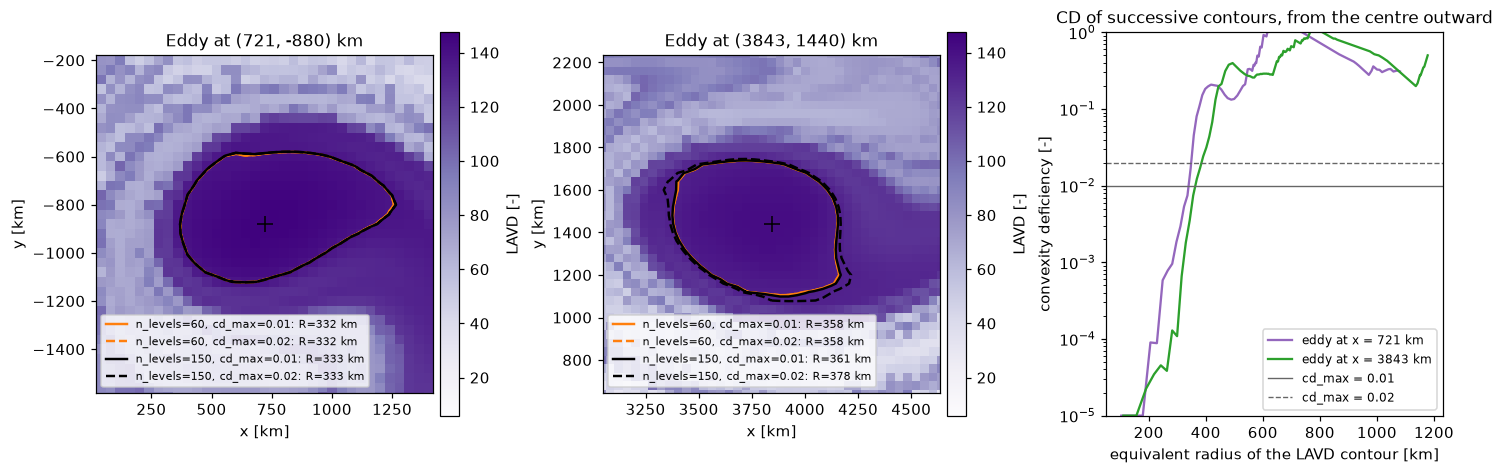

In [22]:
# How does the convexity deficiency grow as the contour level is lowered? (first two eddies found)
import contourpy
from matplotlib.path import Path
from scipy.spatial import ConvexHull

EDDY_KEY = (False, 150, 0.02)                      # setting kept for the rest of the notebook
ref = eddy_sets[EDDY_KEY]
cg = contourpy.contour_generator(np.concatenate([xl, xl + Lx]), yl, np.concatenate([LAVD, LAVD], axis=1),
                                 line_type=contourpy.LineType.Separate)


def cd_profile(e, n=200):
    # R_eq and CD of the closed LAVD contours around eddy e, from the peak outward
    xc = e["xc"] + (Lx if e["xc"] < Lx / 2 else 0.0)          # use the copy away from the seam
    out = []
    for lev in np.linspace(e["peak"], LAVD.min(), n)[1:]:
        hit = [p for p in cg.lines(lev) if np.allclose(p[0], p[-1]) and Path(p).contains_point((xc, e["yc"]))]
        if not hit:
            break
        p = min(hit, key=lk._polygon_area)
        A = lk._polygon_area(p)
        out.append((np.sqrt(A / np.pi), (ConvexHull(p[:-1]).volume - A) / A, lev))
    return np.array(out).reshape(-1, 3)


show = ref[:2]
if not show:
    print("No eddy found with this setting: nothing to compare. Try a shorter T_LAVD or a larger cd_max.")
else:
    styles = {(60, 0.01): ("tab:orange", "-"), (60, 0.02): ("tab:orange", "--"),
              (150, 0.01): ("k", "-"), (150, 0.02): ("k", "--")}
    fig, axes = plt.subplots(1, len(show) + 1, figsize=(4.4 * (len(show) + 1), 4.2), constrained_layout=True)
    for ax, e in zip(axes[:-1], show):
        half = 2.1 * e["r_eq"]
        lk.plot_field(ax, xl, yl, LAVD, kind="lavd", label="LAVD [-]", robust=False)
        for (n_levels, cd_max), (col, ls) in styles.items():
            cands = eddy_sets[(False, n_levels, cd_max)]
            if not cands:
                continue
            match = min(cands, key=lambda q: abs((q["xc"] - e["xc"] + Lx / 2) % Lx - Lx / 2))
            b = match["boundary"]
            ax.plot(b[:, 0], b[:, 1], color=col, ls=ls, lw=1.6,
                    label=f"n_levels={n_levels}, cd_max={cd_max}: R={match['r_eq']:.0f} km")
        ax.plot(e["xc"], e["yc"], "k+", ms=10)
        ax.set(xlim=(e["xc"] - half, e["xc"] + half), ylim=(e["yc"] - half, e["yc"] + half), aspect="equal",
               xlabel="x [km]", ylabel="y [km]", title=f"Eddy at ({e['xc']:.0f}, {e['yc']:.0f}) km")
        ax.legend(fontsize=7, loc="lower left")
    ax = axes[-1]
    for e, col in zip(show, ("tab:purple", "tab:green")):
        prof = cd_profile(e)
        ax.semilogy(prof[:, 0], np.maximum(prof[:, 1], 1e-5), color=col, label=f"eddy at x = {e['xc']:.0f} km")
    for cd_max, ls in ((0.01, "-"), (0.02, "--")):
        ax.axhline(cd_max, color="0.4", ls=ls, lw=0.9, label=f"cd_max = {cd_max}")
    ax.set(xlabel="equivalent radius of the LAVD contour [km]", ylabel="convexity deficiency [-]",
           ylim=(1e-5, 1), title="CD of successive contours, from the centre outward")
    ax.legend(fontsize=8)
    plt.show()

**Discussion.** - **Every setting finds six eddies**, with equivalent radii between about 275 and 380 km. The parameters change the radii by 15% at most.
- **Strict and tolerant rules give identical boundaries.** The right panel shows why: going outward from the centre, the convexity deficiency stays very small and then rises by two orders of magnitude, from $10^{-3}$ to more than $10^{-1}$, between radii of about 300 and 450 km. It never comes back below the threshold, so continuing the scan after the first failure finds nothing.
- Because the rise is so steep, **`cd_max` = 0.01 or 0.02 hardly matters**. What matters more is **`n_levels`**: with only 60 levels the scan steps over the last admissible contour and returns a boundary that can be 50 km too small. Use enough levels that the result no longer changes.
- In the maps the dark, high-LAVD region looks **larger** than the boundary. Look at its shape: it has a tail that wraps around the core. Contours that include the tail are not convex, and the method rejects them. Whether it is right to do so is tested next.
- We keep `n_levels = 150`, `cd_max = 0.02` and the tolerant rule (which is the safer default with noisy data, where small dents in the LAVD field are common).

6 eddies:
  anticyclone centre (   721,   -880) km, R_eq = 333 km, CD = 0.0067, LAVD peak = 146
  cyclone     centre (  3843,   1440) km, R_eq = 378 km, CD = 0.0159, LAVD peak = 142
  anticyclone centre (  6245,  -1320) km, R_eq = 332 km, CD = 0.0160, LAVD peak = 141
  cyclone     centre (  9167,    920) km, R_eq = 333 km, CD = 0.0135, LAVD peak = 145
  anticyclone centre ( 13090,  -1120) km, R_eq = 319 km, CD = 0.0104, LAVD peak = 145
  cyclone     centre ( 16693,    760) km, R_eq = 356 km, CD = 0.0187, LAVD peak = 147


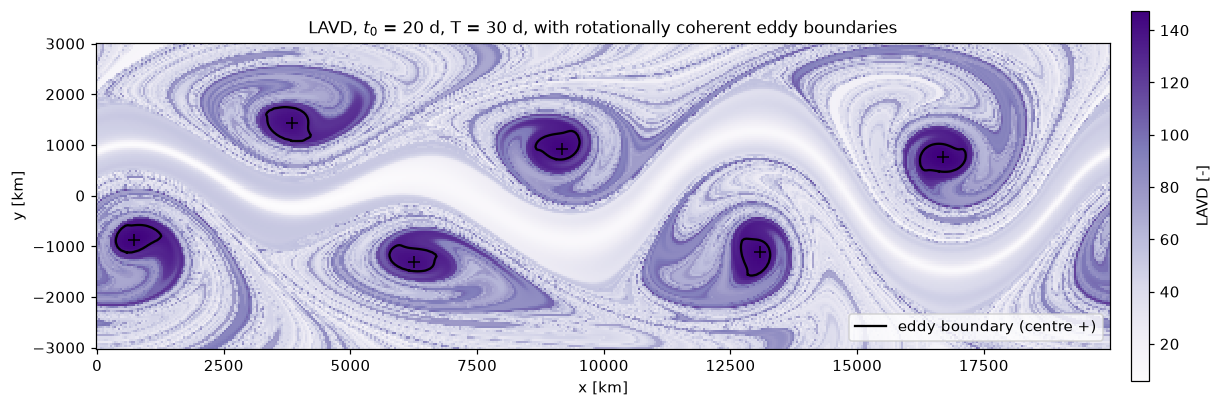

In [23]:
eddies = eddy_sets[EDDY_KEY]
vort_at = lambda e: float(vorticity(e["xc"], e["yc"], T0))
print(f"{len(eddies)} eddies:")
for e in eddies:
    kind = "cyclone    " if vort_at(e) > 0 else "anticyclone"
    print(f"  {kind} centre ({e['xc']:6.0f}, {e['yc']:6.0f}) km, R_eq = {e['r_eq']:.0f} km, CD = {e['cd']:.4f}, LAVD peak = {e['peak']:.0f}")

fig, ax = plt.subplots(figsize=(11, 3.6), constrained_layout=True)
lk.plot_field(ax, xl, yl, LAVD, kind="lavd", label="LAVD [-]", robust=False,
              title=f"LAVD, $t_0$ = {T0:.3g} d, T = {T_LAVD:.3g} d, with rotationally coherent eddy boundaries")
lk.plot_eddies(ax, eddies, color="k", label="eddy boundary (centre +)")
ax.set(xlabel="x [km]", ylabel="y [km]", aspect="equal")
if eddies:
    ax.legend(loc="lower right")
plt.show()

**Are the boundaries really coherent?** The definition promises that the boundary does not filament. Test it: advect every boundary for the full $T$ and compare its perimeter and shape before and after. As a control, do the same with a circle of the same size placed in the chaotic band.

                      perimeter ratio   area ratio   | perimeter ratio of a circle of radius 1.6 R_eq
  eddy x =    721 km           1.10        1.000   |      425.2
  eddy x =   3843 km           1.35        1.000   |      630.2
  eddy x =   6245 km           1.11        1.000   |      418.5
  eddy x =   9167 km           1.10        1.000   |       86.4
  eddy x =  13090 km           1.05        1.000   |       76.2
  eddy x =  16693 km           0.99        1.000   |       75.6
  control circle      >      2776.0   (curve no longer resolved by 2000 points)


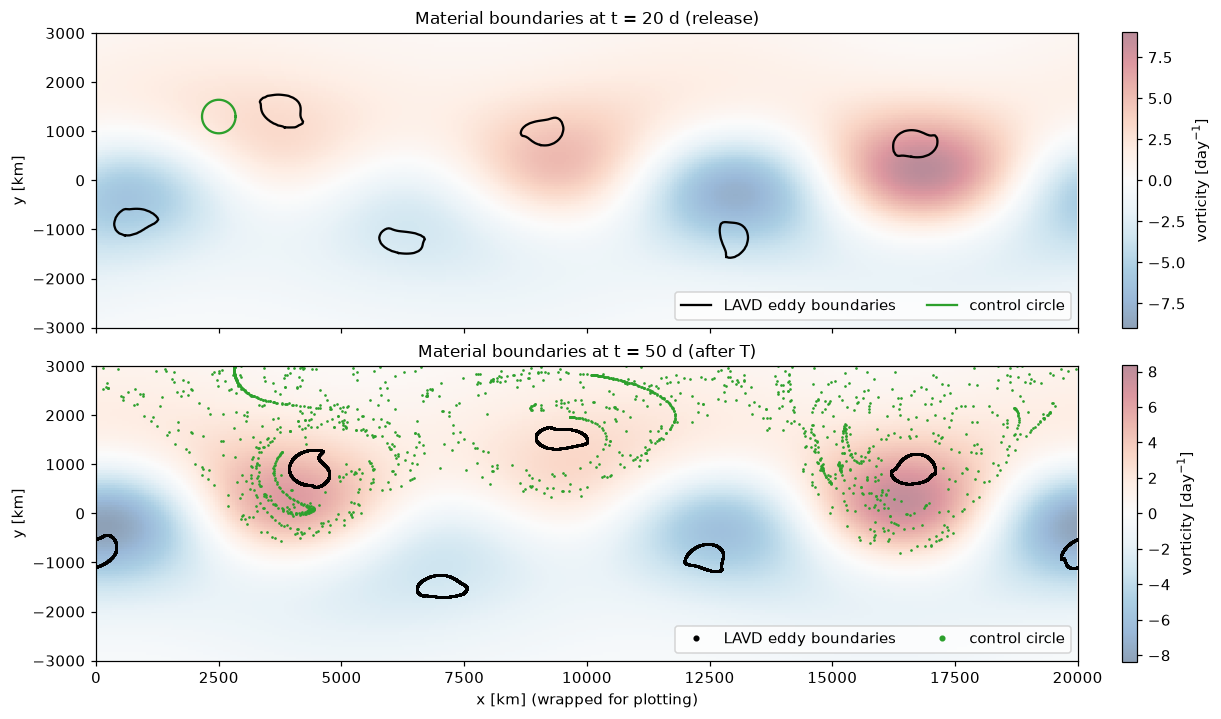

In [24]:
def perimeter(p):
    return np.hypot(np.diff(p[:, 0]), np.diff(p[:, 1])).sum()


def densify(p, n=2000):
    # resample a closed polygon with n points equally spaced along its length
    s = np.concatenate([[0], np.cumsum(np.hypot(np.diff(p[:, 0]), np.diff(p[:, 1])))])
    si = np.linspace(0, s[-1], n)
    return np.column_stack([np.interp(si, s, p[:, 0]), np.interp(si, s, p[:, 1])])


def stretch(b):
    # advect a closed curve for T_LAVD; return final curve, perimeter ratio, area ratio
    b = densify(b)
    bx, by = lk.advect(b[:, 0], b[:, 1], T0, T_LAVD, DT_TRAJ, velocity)
    bf = np.column_stack([bx, by])
    return bf, perimeter(bf) / perimeter(b), lk._polygon_area(bf) / lk._polygon_area(b)


th = np.linspace(0, 2 * np.pi, 400)
circle = lambda xc, yc, r: np.column_stack([xc + r * np.cos(th), yc + r * np.sin(th)])
r_mean = np.mean([e["r_eq"] for e in eddies]) if eddies else R_BLOB
control = circle(*blobs["chaotic band"], r_mean)   # same place as the "chaotic band" blob of B2

final = []
print("                      perimeter ratio   area ratio   | perimeter ratio of a circle of radius 1.6 R_eq")
for e in eddies:
    bf, pr, ar = stretch(e["boundary"])
    final.append(bf)
    _, pr_big, _ = stretch(circle(e["xc"], e["yc"], 1.6 * e["r_eq"]))
    print(f"  eddy x = {e['xc']:6.0f} km {pr:14.2f} {ar:12.3f}   | {pr_big:10.1f}")
bf, pr, _ = stretch(control)
final.append(bf)
resolved = np.hypot(np.diff(bf[:, 0]), np.diff(bf[:, 1])).max() < 0.1 * Lx
print(f"  control circle      {'' if resolved else '> '}{pr:11.1f}" + ("" if resolved else "   (curve no longer resolved by 2000 points)"))

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, constrained_layout=True)
for ax, t, title in zip(axes, (T0, T0 + T_LAVD), ("release", "after T")):
    lk.plot_field(ax, xg, yg, vorticity(XG, YG, t), kind="vorticity", robust=False, alpha=0.45,
                  label="vorticity [day$^{-1}$]", title=f"Material boundaries at t = {t:.3g} d ({title})")
    ax.set(ylabel="y [km]", aspect="equal", xlim=(0, Lx), ylim=(-Y_MAX, Y_MAX))
lk.plot_eddies(axes[0], eddies, color="k", centers=False, label="LAVD eddy boundaries")
axes[0].plot(control[:, 0], control[:, 1], color="tab:green", lw=1.5, label="control circle")
for n, bf in enumerate(final[:-1]):
    axes[1].plot(np.mod(bf[:, 0], Lx), bf[:, 1], "k.", ms=1.5, label="LAVD eddy boundaries" if n == 0 else None)
axes[1].plot(np.mod(final[-1][:, 0], Lx), final[-1][:, 1], ".", color="tab:green", ms=1.5, label="control circle")
for ax in axes:
    ax.legend(loc="lower right", markerscale=4, ncol=2)
axes[-1].set_xlabel("x [km] (wrapped for plotting)")
plt.show()

**Discussion.** - **The six boundaries stay coherent.** After 30 days, about a dozen rotations, their perimeters have changed by between −1% and +35%, and the enclosed areas are conserved to three digits (as they must be in a non-divergent flow, which is also a check on the integration). Three are cyclones north of the jet and three anticyclones south of it.
- **The control circle** of the same size in the chaotic band is stretched by a factor of more than 2000 and spread over the whole northern side.
- **The last column answers the question of B8a.** A circle 1.6 times larger than each boundary, which covers the dark high-LAVD area seen in the map, is stretched by a factor of 75 to 630. So the high-LAVD water outside the boundary rotates a lot but does *not* stay together. The extracted boundaries are small because the coherent cores are small, not because the extraction is too strict.
- A high value of the LAVD is therefore not enough; the *shape* of the contours (convexity) carries the information about coherence. And always test a detected boundary by advecting it. It is cheap, and it is the definition.

<a id="B9"></a>
## B9. Okubo–Weiss versus LAVD (→ [A8](00-lagrangian-theory.ipynb#A8))

Compute $W$ (A8.1) from the gridded velocity at $t_0$ by centred differences, as one would from data, draw the usual threshold $W=-0.2\,\sigma_W$ (A8.3) and overlay the LAVD boundaries of B8.

sigma_W = 14.47 1/day^2, threshold = -2.89 1/day^2
  LAVD centre [km]      R_LAVD   R_OW    OW minimum [km]     offset of the minimum
  (   721,   -880)     333    1353    (   600,   -350)         543 km
  (  3843,   1440)     378     957    (  3803,    900)         541 km
  (  6245,  -1320)     332     952    (  6355,   -800)         532 km
  (  9167,    920)     333    1309    (  9407,    450)         528 km
  ( 13090,  -1120)     319    1393    ( 13010,   -250)         874 km
  ( 16693,    760)     356    1420    ( 16863,    200)         585 km


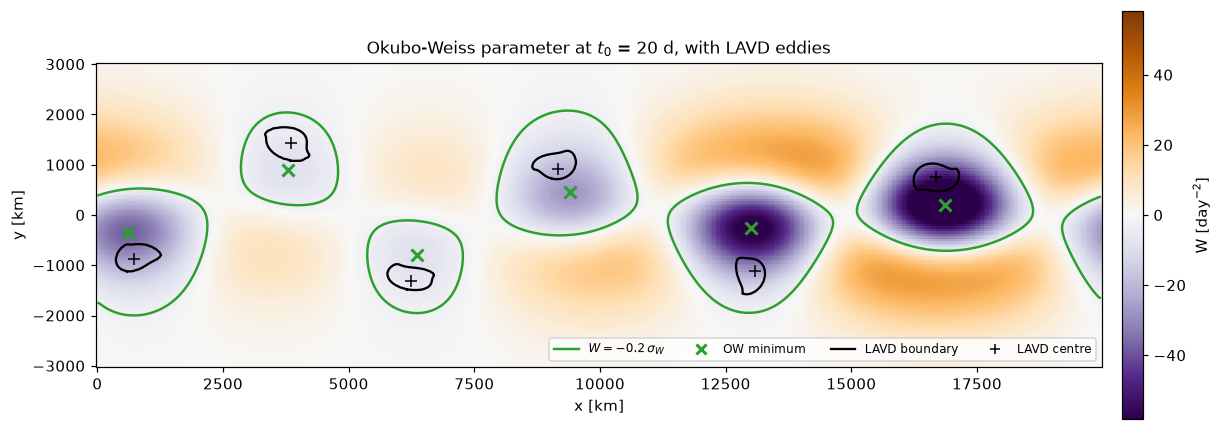


Total run time: 72 s


In [25]:
U0g, V0g = velocity(XG, YG, T0)
dxg, dyg = xg[1] - xg[0], yg[1] - yg[0]
W, om, sn, ss = lk.okubo_weiss(U0g, V0g, dxg, dyg)
W_thr = -0.2 * W.std()

# Okubo-Weiss "eddies": connected regions below the threshold (domain tiled once for periodicity)
labels, _ = ndimage.label(np.tile(W < W_thr, (1, 2)))
x2 = np.concatenate([xg, xg + Lx])
W2 = np.tile(W, (1, 2))
print(f"sigma_W = {W.std():.2f} 1/day^2, threshold = {W_thr:.2f} 1/day^2")
print("  LAVD centre [km]      R_LAVD   R_OW    OW minimum [km]     offset of the minimum")
ow_minima = []
for e in eddies:
    xc = e["xc"] + (Lx if e["xc"] < Lx / 2 else 0.0)
    lab = labels[np.argmin(np.abs(yg - e["yc"])), np.argmin(np.abs(x2 - xc))]
    if lab == 0:
        print(f"  ({e['xc']:6.0f}, {e['yc']:6.0f})  {e['r_eq']:6.0f}   centre is not inside an OW region")
        continue
    region = labels == lab
    r_ow = np.sqrt(region.sum() * dxg * dyg / np.pi)
    j, i = np.unravel_index(np.argmin(np.where(region, W2, np.inf)), W2.shape)
    xm, ym = np.mod(x2[i], Lx), yg[j]
    ow_minima.append((xm, ym))
    off = np.hypot((xm - e["xc"] + Lx / 2) % Lx - Lx / 2, ym - e["yc"])
    print(f"  ({e['xc']:6.0f}, {e['yc']:6.0f})  {e['r_eq']:6.0f}  {r_ow:6.0f}    ({xm:6.0f}, {ym:6.0f})      {off:6.0f} km")

fig, ax = plt.subplots(figsize=(11, 3.8), constrained_layout=True)
lk.plot_field(ax, xg, yg, W, kind="okubo_weiss", label="W [day$^{-2}$]",
              title=f"Okubo-Weiss parameter at $t_0$ = {T0:.3g} d, with LAVD eddies")
ax.contour(xg, yg, W, levels=[W_thr], colors="tab:green", linewidths=1.6, linestyles="-")
lk.plot_eddies(ax, eddies, color="k")
if ow_minima:
    ax.plot(*np.array(ow_minima).T, "x", color="tab:green", ms=8, mew=2)
ax.legend(handles=[Line2D([], [], color="tab:green", lw=1.6, label=r"$W=-0.2\,\sigma_W$"),
                   Line2D([], [], color="tab:green", marker="x", ls="", mew=2, label="OW minimum"),
                   Line2D([], [], color="k", lw=1.5, label="LAVD boundary"),
                   Line2D([], [], color="k", marker="+", ls="", label="LAVD centre")],
          loc="lower right", ncol=4, fontsize=8)
ax.set(xlabel="x [km]", ylabel="y [km]", aspect="equal")
plt.show()
print(f"\nTotal run time: {time.time() - t_start:.0f} s")

**Discussion.** - Okubo–Weiss finds six regions, one per eddy, so as a detector it works here. As a description of the eddies it does not:
  - **Size.** The regions $W<-0.2\,\sigma_W$ have equivalent radii of 950–1420 km, three to four times the LAVD radii (about ten times the area). They extend to the edge of the jet. B8 showed that a circle only 1.6 times larger than the LAVD boundary is already torn apart, so most of the water inside an Okubo–Weiss "eddy" does not stay in it.
  - **Position.** The minima of $W$ are displaced by 530–870 km from the LAVD centres, all of them towards the jet axis. $W$ is most negative where the instantaneous vorticity is strongest, next to the jet. The water that actually recirculates is centred further away from the jet.
- The reason is the one given in [A8](00-lagrangian-theory.ipynb#A8): $W$ describes the velocity gradient at one instant, in one frame. In a flow where the pattern moves through the water, that is not the same thing as following the water.
- With radar data there is one more problem, which this smooth analytic field hides: $W$ contains squared derivatives of the velocity and is very sensitive to noise (Exercise 6).

### Summary: the diagnostics and their pitfalls with real data

| Diagnostic | What it gave on the Bickley jet | Main pitfalls with HF-radar / model data (notebook 02) |
|---|---|---|
| Trajectories | regular in eddy and jet cores, chaotic in between | particles leave the coverage; gaps; interpolation below grid scale; tides |
| Absolute dispersion, $T_L$, $K$ | meridional saturation (barrier), zonal shear dispersion; $K$ not meaningful | inhomogeneity and mean shear; survivors only; record shorter than $T_L$ |
| Relative dispersion | exponential, then a transition that mimics a power law | regimes mixed at fixed time; small footprint gives early saturation |
| FSLE statistic | plateau (non-local regime) up to large scales | few pairs at large $\delta$; below the grid spacing it measures the interpolation |
| FTLE map | ridges bound the eddies and the jet; low in cores | $T$ limited by residence time; aliasing; divergence; edges |
| FSLE map | same lines as backward FTLE, sharper, zero in cores | choice of $\delta_0,\delta_f$; exit before $\delta_f$ must be masked, not set to 0 |
| LAVD | the six eddies, with material boundaries | noisy vorticity; $\bar\omega$ over a small, gappy domain; eddies larger than the footprint |
| Okubo–Weiss | finds the same six, with different shapes | noise amplification; arbitrary threshold; not objective; not material |

<a id="B10"></a>
## B10. Exercises

Solutions are in `solutions/01_solutions.ipynb`.

1. **Convergence.** Halve `DT` and recompute the forward FTLE of B6. How much does the map change? Then keep `DT` and double the grid resolution. Which of the two changes the ridges more, and why (see [A9](00-lagrangian-theory.ipynb#A9))? Do the same for one trajectory released in the chaotic band and one in an eddy core.
2. **Switch the chaos off.** Create `lk.BickleyJet(eps=(0, 0, 0.3))`, which has a single wave and is steady in this frame. Repeat the blob experiment of B2 and the FTLE of B6. What happens to the chaotic band? What do the FTLE ridges look like in a steady flow, and what do they tell you about using FTLE in shear?
3. **FTLE versus integration time.** Compute the domain-mean forward FTLE for $T=2,5,10,20,30,40$ days and plot it against $T$. Why does it decrease? What value do you expect for $T\to0$? (Hint: [A5](00-lagrangian-theory.ipynb#A5), limits in $T$.)
4. **Is the jet a barrier?** Release 2000 particles on the line $y=+300$ km and 2000 on $y=+1300$ km. Count how many are south of $y=-500$ km after 40 days. Is a fixed latitude a valid way to decide that a particle has crossed the jet? Look at the FTLE map of B6 and propose a better criterion. (Hint: the vorticity has opposite signs on the two sides of the jet.)
5. **LAVD parameters.** Recompute the LAVD with $T=10$ and $T=60$ days and extract eddies with `cd_max` = 0.005, 0.02 and 0.1. How do the number and size of the eddies change? What does a larger `cd_max` allow, and how would you test whether the larger boundaries are still coherent?
6. **A preview of radar errors.** Add 5% noise to the velocity (Gaussian, standard deviation 5% of the rms speed, on a 100 km, 6-hourly grid, using `lk.sample_to_dataset` and `lk.grid_interpolator`). Recompute the backward FTLE and the Okubo–Weiss parameter. Which one is more robust, and why?

## References

- Artale, V., Boffetta, G., Celani, A., Cencini, M., & Vulpiani, A. (1997). Dispersion of passive tracers in closed basins: Beyond the diffusion coefficient. *Physics of Fluids*, 9(11), 3162–3171. https://doi.org/10.1063/1.869433
- Aurell, E., Boffetta, G., Crisanti, A., Paladin, G., & Vulpiani, A. (1997). Predictability in the large: an extension of the concept of Lyapunov exponent. *Journal of Physics A: Mathematical and General*, 30(1), 1–26. https://doi.org/10.1088/0305-4470/30/1/003
- Babiano, A., Basdevant, C., Le Roy, P., & Sadourny, R. (1990). Relative dispersion in two-dimensional turbulence. *Journal of Fluid Mechanics*, 214, 535–557. https://doi.org/10.1017/S0022112090000258
- Bennett, A. F. (1984). Relative dispersion: local and nonlocal dynamics. *Journal of the Atmospheric Sciences*, 41(11), 1881–1886. https://doi.org/10.1175/1520-0469(1984)041<1881:RDLAND>2.0.CO;2
- d'Ovidio, F., Fernández, V., Hernández-García, E., & López, C. (2004). Mixing structures in the Mediterranean Sea from finite-size Lyapunov exponents. *Geophysical Research Letters*, 31(17), L17203. https://doi.org/10.1029/2004GL020328
- Hadjighasem, A., Farazmand, M., Blazevski, D., Froyland, G., & Haller, G. (2017). A critical comparison of Lagrangian methods for coherent structure detection. *Chaos*, 27(5), 053104. https://doi.org/10.1063/1.4982720
- Haller, G. (2015). Lagrangian coherent structures. *Annual Review of Fluid Mechanics*, 47, 137–162. https://doi.org/10.1146/annurev-fluid-010313-141322
- Haller, G., Hadjighasem, A., Farazmand, M., & Huhn, F. (2016). Defining coherent vortices objectively from the vorticity. *Journal of Fluid Mechanics*, 795, 136–173. https://doi.org/10.1017/jfm.2016.151
- LaCasce, J. H. (2008). Statistics from Lagrangian observations. *Progress in Oceanography*, 77(1), 1–29. https://doi.org/10.1016/j.pocean.2008.02.002
- Okubo, A. (1970). Horizontal dispersion of floatable particles in the vicinity of velocity singularities such as convergences. *Deep Sea Research and Oceanographic Abstracts*, 17(3), 445–454. https://doi.org/10.1016/0011-7471(70)90059-8
- Rypina, I. I., Brown, M. G., Beron-Vera, F. J., Koçak, H., Olascoaga, M. J., & Udovydchenkov, I. A. (2007). On the Lagrangian dynamics of atmospheric zonal jets and the permeability of the stratospheric polar vortex. *Journal of the Atmospheric Sciences*, 64(10), 3595–3610. https://doi.org/10.1175/JAS4036.1
- Shadden, S. C., Lekien, F., & Marsden, J. E. (2005). Definition and properties of Lagrangian coherent structures from finite-time Lyapunov exponents in two-dimensional aperiodic flows. *Physica D*, 212(3–4), 271–304. https://doi.org/10.1016/j.physd.2005.10.007
- Taylor, G. I. (1921). Diffusion by continuous movements. *Proceedings of the London Mathematical Society*, s2-20(1), 196–212 (issue dated 1922). https://doi.org/10.1112/plms/s2-20.1.196
- Weiss, J. (1991). The dynamics of enstrophy transfer in two-dimensional hydrodynamics. *Physica D*, 48(2–3), 273–294. https://doi.org/10.1016/0167-2789(91)90088-Q

Software: OceanParcels, https://parcels-code.org (version 4 is used in B2b).